# Metal wall processing

Tag positions follow `location_logic.md`.

In [132]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../metal_wall_data")   # run from organized_multitag/metal_wall_processing
TILE_CM = 46.0      # 1 ft 6 in tiles
ROWS_PER_COL = 8    # labels 1-8 in column 0, 9-16 in column 1, ...
N_LABELS = 136

## Positions: label -> grid -> cm

In [133]:
def label_to_grid(label):
    """Floor label ('69' or 'under-72') -> (col, row) intersection index."""
    label = str(label).strip()
    offset = 0
    if label.startswith("under-"):
        label, offset = label[len("under-"):], 1
    n = int(label)
    return (n - 1) // ROWS_PER_COL, (n - 1) % ROWS_PER_COL + offset


def load_positions(exp_dir):
    pos = pd.read_csv(Path(exp_dir) / "positions.txt", skipinitialspace=True, dtype=str)
    pos.columns = [c.strip() for c in pos.columns]
    pos["name"] = [p if p == "screen" else f"Tag{p}" for p in pos["Tag"]]
    pos[["col", "row"]] = [label_to_grid(l) for l in pos["Position"]]
    pos["x_cm"] = pos["col"] * TILE_CM
    pos["y_cm"] = pos["row"] * TILE_CM
    return pos.set_index("name")


def screen_segment(pos):
    """Screen is a wall at the screen label's column spanning the tags' full y-extent (all 5 rows)."""
    tags = pos.drop(index="screen")
    x = pos.loc["screen", "x_cm"]
    return (x, tags["y_cm"].min()), (x, tags["y_cm"].max())


exp_dirs = sorted(p for p in DATA_DIR.iterdir() if (p / "positions.txt").exists())
positions = {d.name: load_positions(d) for d in exp_dirs}
positions[exp_dirs[0].name]

,Tag,Position,col,row,x_cm,y_cm
name,,,,,,
Tag1,1,69,8,4,368.0,184.0
Tag2,2,70,8,5,368.0,230.0
Tag3,3,71,8,6,368.0,276.0
Tag4,4,72,8,7,368.0,322.0
Tag5,5,under-72,8,8,368.0,368.0
Tag6,6,85,10,4,460.0,184.0
Tag7,7,86,10,5,460.0,230.0
Tag8,8,87,10,6,460.0,276.0
Tag9,9,88,10,7,460.0,322.0


## CSV format check

The `Channel_*_voltages` columns hold raw sample lists and make the files ~500 MB, so they're skipped here.

In [134]:
def load_csv(exp_dir, with_voltages=False):
    f = next(Path(exp_dir).glob("*.csv"))
    cols = pd.read_csv(f, nrows=0).columns
    usecols = cols if with_voltages else [c for c in cols if "voltages" not in c.lower()]
    return pd.read_csv(f, usecols=usecols)


data = {d.name: load_csv(d) for d in exp_dirs}
for name, df in data.items():
    pairs = df.groupby(["Rx", "Tx"]).size()
    tags = set(df["Rx"]) | set(df["Tx"])
    missing = tags - set(positions[name].index)
    print(f"exp {name}: {len(df)} rows, {len(tags)} tags, {len(pairs)} Rx/Tx pairs, "
          f"{df['Frequency (MHz)'].nunique()} freqs, runs={sorted(df['Run Exp Num'].unique())}, "
          f"rows/pair={pairs.unique()}, tags without position={missing or 'none'}")
data[exp_dirs[0].name].head()

exp 1: 13860 rows, 15 tags, 210 Rx/Tx pairs, 22 freqs, runs=[np.int64(0), np.int64(1), np.int64(2)], rows/pair=[66], tags without position=none
exp 2: 13860 rows, 15 tags, 210 Rx/Tx pairs, 22 freqs, runs=[np.int64(0), np.int64(1), np.int64(2)], rows/pair=[66], tags without position=none


,Rx,Tx,MPP Start Time (s),MPP Stop Time (s),Frequency (MHz),Run Exp Num,MPP Repetition,Unidirectional Phase (deg),Unidirectional V,Unidirectional beta,...,Sample Rate (Hz),Dwell (samples),Esync Rho,Esync SNR (dB),Channel_1_median,Channel_3_median,Channel_4_median,Channel_6_median,Channel_7_median,Channel_8_median
0,Tag1,Tag10,1.793152e+09,1.793152e+09,775,0,1,73.703786,31.380329,0.466268,...,40016.006403,120.048019,0.981,20.8,77.286946,77.973602,74.464027,75.684749,75.532158,76.523995
1,Tag1,Tag15,1.793152e+09,1.793152e+09,775,0,1,-110.150726,31.111388,0.396807,...,40016.006403,120.048019,0.981,20.8,74.921798,73.319600,76.829175,75.761044,75.761044,74.921798
2,Tag1,Tag16,1.793152e+09,1.793152e+09,775,0,1,112.027752,33.015480,1.503351,...,40017.340848,120.052023,0.981,20.8,85.603113,82.475013,75.455863,83.161669,73.701076,84.916457
3,Tag1,Tag17,1.793152e+09,1.793152e+09,775,0,1,-120.553922,31.125576,0.767647,...,40017.340848,120.052023,0.981,20.8,73.624781,72.251469,77.744717,76.829175,74.998093,75.150683
4,Tag1,Tag18,1.793152e+09,1.793152e+09,775,0,1,-8.455642,31.025622,0.025619,...,40017.340848,120.052023,0.981,20.8,74.998093,75.074388,74.998093,74.921798,75.150683,74.845502


## Plot tag positions

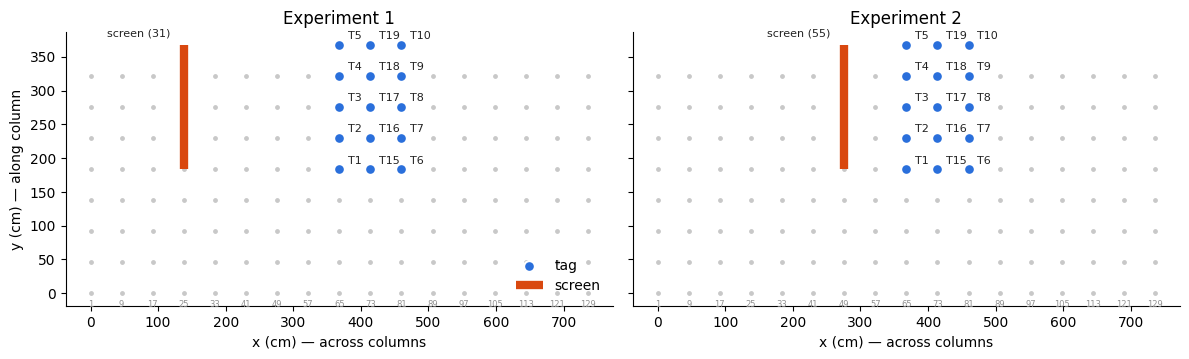

In [135]:
fig, axes = plt.subplots(1, len(positions), figsize=(6 * len(positions), 5), sharex=True, sharey=True)
axes = np.atleast_1d(axes)

# all labelled intersections as a faint reference grid
grid = np.array([label_to_grid(n) for n in range(1, N_LABELS + 1)]) * TILE_CM

for ax, (name, pos) in zip(axes, positions.items()):
    ax.scatter(grid[:, 0], grid[:, 1], s=6, color="#c8c8c8", zorder=1)
    for n in range(1, N_LABELS + 1, ROWS_PER_COL):  # label the first row of each column
        x, y = np.array(label_to_grid(n)) * TILE_CM
        ax.annotate(str(n), (x, y), xytext=(0, -10), textcoords="offset points",
                    ha="center", fontsize=6, color="#909090")

    tags = pos.drop(index="screen", errors="ignore")
    ax.scatter(tags["x_cm"], tags["y_cm"], s=60, color="#2a6fdb", edgecolor="white",
               linewidth=1.5, zorder=3, label="tag")
    for tag, r in tags.iterrows():
        ax.annotate(tag.replace("Tag", "T"), (r["x_cm"], r["y_cm"]), xytext=(6, 4),
                    textcoords="offset points", fontsize=8, color="#222222")

    if "screen" in pos.index:
        s = pos.loc["screen"]
        (x0, y0), (x1, y1) = screen_segment(pos)
        ax.plot([x0, x1], [y0, y1], color="#d9480f", linewidth=6, solid_capstyle="butt",
                zorder=2, label="screen")
        ax.annotate(f"screen ({s['Position']})", (x1, y1), xytext=(-10, 6),
                    textcoords="offset points", ha="right", fontsize=8, color="#222222")

    ax.set_title(f"Experiment {name}")
    ax.set_xlabel("x (cm) — across columns")
    ax.set_aspect("equal")
    ax.grid(False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("y (cm) — along column")
axes[0].legend(loc="lower right", frameon=False)
fig.tight_layout()
plt.show()

## Bidirectional phase and attenuation: `[exp][T1][T2][freq]`

For a pair `1 < 2` (by tag number), subscript `1` is the row measured with **Rx = T1** (Tx = T2) and `2` the row with **Rx = T2** (Tx = T1), matched per run:

$$\hat\alpha_{12} = \frac{1}{2}\left(\frac{\hat\beta_1}{\hat V_2} + \frac{\hat\beta_2}{\hat V_1}\right) \qquad
\hat\theta_{12} = \left(\frac{\hat\Theta_1 + \hat\Theta_2}{2}\right) \bmod \pi$$

- $\hat\Theta$ = `Unidirectional Phase (deg)` converted to radians, so $\hat\theta_{12}$ (`theta_data`, column `THETA`) is in **radians** in $[0, \pi)$
- $\hat\beta$ = `Unidirectional beta`, $\hat V$ = `Unidirectional V` → $\hat\alpha_{12}$ (`alpha_data`)

Each entry is a numpy array with one value per run (index = `Run Exp Num`).

In [136]:
def tag_num(name):
    return int(str(name).replace("Tag", ""))


def bidirectional(df):
    """Join each Rx=a/Tx=b row with its Rx=b/Tx=a counterpart (a < b) and compute THETA, alpha."""
    keep = ["Rx", "Tx", "Frequency (MHz)", "Run Exp Num",
            "Unidirectional Phase (deg)", "Unidirectional V", "Unidirectional beta"]
    d = df[keep]
    fwd = d[d["Rx"].map(tag_num) < d["Tx"].map(tag_num)]    # Rx = a, Tx = b
    rev = d[d["Rx"].map(tag_num) > d["Tx"].map(tag_num)]    # Rx = b, Tx = a
    m = fwd.merge(rev, left_on=["Rx", "Tx", "Frequency (MHz)", "Run Exp Num"],
                  right_on=["Tx", "Rx", "Frequency (MHz)", "Run Exp Num"],
                  suffixes=("_a", "_b"), validate="one_to_one")
    th_a = np.deg2rad(m["Unidirectional Phase (deg)_a"])
    th_b = np.deg2rad(m["Unidirectional Phase (deg)_b"])
    m["THETA"] = ((th_a + th_b) / 2) % np.pi
    m["alpha"] = 0.5 * (m["Unidirectional beta_a"] / m["Unidirectional V_b"]
                        + m["Unidirectional beta_b"] / m["Unidirectional V_a"])
    return m.rename(columns={"Rx_a": "T1", "Tx_a": "T2"})


def to_nested(m, col):
    """-> {T1: {T2: {freq: array over runs}}} with tags in numeric order."""
    out = {}
    m = m.sort_values(["T1", "T2", "Frequency (MHz)", "Run Exp Num"],
                      key=lambda s: s.map(tag_num) if s.name in ("T1", "T2") else s)
    for (t1, t2, f), g in m.groupby(["T1", "T2", "Frequency (MHz)"], sort=False):
        out.setdefault(t1, {}).setdefault(t2, {})[int(f)] = g[col].to_numpy()
    return out


bidir = {name: bidirectional(df) for name, df in data.items()}
theta_data = {name: to_nested(m, "THETA") for name, m in bidir.items()}
alpha_data = {name: to_nested(m, "alpha") for name, m in bidir.items()}

ex = exp_dirs[0].name
print(f"exp {ex}: {len(bidir[ex])} (pair, freq, run) rows, "
      f"{sum(len(d) for d in theta_data[ex].values())} pairs")
print("THETA[Tag1][Tag2][775] =", theta_data[ex]["Tag1"]["Tag2"][775])
print("alpha[Tag1][Tag2][775] =", alpha_data[ex]["Tag1"]["Tag2"][775])

exp 1: 6930 (pair, freq, run) rows, 105 pairs
THETA[Tag1][Tag2][775] = [1.0303469  0.75161615 0.70143898]
alpha[Tag1][Tag2][775] = [0.03403188 0.02720771 0.02656764]


## Plot settings and helpers

Settings used by every section below:

- `FREQ_RANGE`: frequency range (MHz, inclusive) of the 2D plots; `FREQ_RANGE_3D`: of the 3D plots
- `UNWRAP_3D`: remove the mod-π jumps in the 3D plots (off by default)

Links are given as **slots** `(i, j)` = the i-th and j-th tag of a column, counted from 1 along the column. The same slot is
used in every tag column: `(1, 2)` → T1–T2 (col 8), T15–T16 (col 9), T6–T7 (col 10). A link is `|j − i| × 46 cm` long.

**Perpendicular links** (pass `perp_gap=g`) run across the tag columns, perpendicular to the wall/screen: same row, tag columns
`g` apart (counted outward from the screen: col 8 → 9 → 10). Links are then given as **rows** (1–5, counted along the column):
row 5 with `perp_gap=1` → T5–T19 (cols 8–9), T19–T10 (cols 9–10); with `perp_gap=2` → T5–T10 (cols 8–10).
A perpendicular link is `g × 46 cm` long and its distance from the screen is that of its **midpoint**.

Plots (each section below calls them for one link length):

1. `plot_link_panels(data, ylabel, links=...)` — 2D, θ̂ vs frequency, one panel per (experiment, tag column),
   sorted by distance from the screen. Dots = individual runs, line = circular mean over runs (on the mod-π circle).
2. `plot_link_vs_distance(link, distances)` — 2D, one link slot at several distances from the screen
   (`available_distances(link)` lists them). One colour per tag pair (the same link in both experiments shares a colour), solid = exp 2, dashed = exp 1.
   `unwrap=True` removes the mod-π jumps, the same way as in the 3D plot (see below); add `zero_start=True` to
   shift each distance's line so it starts at 0 at the first frequency (compares slopes, not offsets).
3. `plot_link_vs_distance_3d(link, distances, ...)` — interactive 3D, x = frequency, y = distance from the screen,
   z = θ̂. Drag to rotate, scroll to zoom, click legend entries to hide/show lines.
   - `surface=True` / `floor_map=True`: surface coloured by θ̂, contours projected onto the floor as a frequency × distance map.
   - `unwrap=True` (default `UNWRAP_3D`): unwrap across distance at the lowest frequency, then along frequency, so the
     slope vs frequency (≈ path length) is visible. The absolute offset is only defined up to a multiple of π.
     `zero_start=True` (with unwrap) starts every line at 0, as in the 2D plot.
     Without unwrapping the raw mod-π phase uses a cyclic colour scale (0 and π get the same colour).
   - `connect=True`: grey wireframe across distance; `show_runs=True`: individual runs.

In [137]:
FREQ_RANGE = (775, 995)   # MHz, inclusive (min, max)
# FREQ_RANGE = (915, 920)   # MHz, inclusive (min, max)

LINK_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
               "#e87ba4", "#008300", "#6250d6", "#e34948"]  # fixed categorical order, one per link


def column_links(pos, links):
    """{grid col: [(Ta, Tb), ...]} for the requested (i, j) slots, tags ordered by row."""
    tags = pos.drop(index="screen").sort_values("row")
    return {col: [(g.index[i - 1], g.index[j - 1]) for i, j in links] for col, g in tags.groupby("col")}


def perp_links(pos, rows, gap):
    """{(col_a, col_b): [(Ta, Tb), ...]} perpendicular to the screen: same row, tag columns `gap` apart.
    Rows are counted from 1 along the column; columns are counted outward from the screen."""
    tags = pos.drop(index="screen")
    screen_col = pos.loc["screen", "col"]
    cols = sorted(tags["col"].unique(), key=lambda c: abs(c - screen_col))
    all_rows = sorted(tags["row"].unique())
    at = {(c, r): t for t, c, r in zip(tags.index, tags["col"], tags["row"])}
    return {(ca, cb): [(at[ca, all_rows[r - 1]], at[cb, all_rows[r - 1]]) for r in rows]
            for ca, cb in zip(cols, cols[gap:])}


def link_groups(data, links, perp_gap=None):
    """[(dist_cm, exp, where, dist_label, [(Ta, Tb), ...])] sorted by distance from the screen.
    parallel (perp_gap=None): links = slots (i, j), one group per tag column, dist = the column's distance
    perpendicular           : links = rows, one group per column pair perp_gap apart, dist = link midpoint"""
    out = []
    for exp in data:
        pos = positions[exp]
        screen_col = pos.loc["screen", "col"]
        if perp_gap is None:
            for col, col_links in column_links(pos, links).items():
                dist = abs(col - screen_col) * TILE_CM
                out.append((dist, exp, f"column {col}", f"{dist:.0f} cm", col_links))
        else:
            for (ca, cb), pair_links in perp_links(pos, links, perp_gap).items():
                da, db = abs(ca - screen_col) * TILE_CM, abs(cb - screen_col) * TILE_CM
                out.append(((da + db) / 2, exp, f"columns {ca}–{cb}", f"{da:.0f}–{db:.0f} cm", pair_links))
    return sorted(out, key=lambda g: g[:2])


def check_link_length(links, length_cm):
    """Every (i, j) slot must be length_cm apart (46 cm per row)."""
    bad = [l for l in links if not np.isclose(abs(l[1] - l[0]) * TILE_CM, length_cm)]
    assert not bad, f"{bad} are not {length_cm:.0f} cm links"


def get_link(d, ta, tb):
    t1, t2 = sorted((ta, tb), key=tag_num)
    return d[t1][t2]


def circmean_mod_pi(x):
    return (np.angle(np.mean(np.exp(2j * np.asarray(x)))) / 2) % np.pi


def plot_link_panels(data, ylabel, agg=np.mean, ylim=None, yticks=None,
                     links=((1, 2),), freq_range=None, n_cols=3, title=None, perp_gap=None):
    """One panel per (experiment, tag column), sorted by distance from the screen.
    data = {exp: {T1: {T2: {freq: array over runs}}}}; agg reduces the runs to the plotted line.
    perp_gap: plot perpendicular links instead, links = rows, one panel per column pair perp_gap apart."""
    assert len(links) <= len(LINK_COLORS), f"at most {len(LINK_COLORS)} links per plot"
    freq_range = FREQ_RANGE if freq_range is None else freq_range
    panels = link_groups(data, links, perp_gap)
    n_rows = -(-len(panels) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.8 * n_rows),
                             sharex=True, sharey=True, squeeze=False)

    for i, (dist, exp, where, dist_label, col_links) in enumerate(panels):
        r, c = divmod(i, n_cols)
        ax = axes[r, c]
        for color, (ta, tb) in zip(LINK_COLORS, col_links):
            fd = get_link(data[exp], ta, tb)
            freqs = np.array([f for f in sorted(fd) if freq_range[0] <= f <= freq_range[1]])
            runs = np.stack([fd[f] for f in freqs])           # (n_freq, n_runs)
            ax.scatter(np.repeat(freqs, runs.shape[1]), runs.ravel(), s=8, color=color, alpha=0.35, linewidths=0)
            ax.plot(freqs, [agg(v) for v in runs], color=color, linewidth=2, marker="o",
                    markersize=4, label=f"{ta.replace('Tag', 'T')}–{tb.replace('Tag', 'T')}")
        ax.set_title(f"{dist_label} from screen (exp {exp}, {where})", fontsize=10)
        if ylim is not None:
            ax.set_ylim(*ylim)
        if yticks is not None:
            ax.set_yticks(*yticks)
        ax.set_xticks(freqs)                      # a labelled tick at every measured frequency
        ax.tick_params(axis="x", labelrotation=90, labelsize=8, labelbottom=True)
        ax.grid(color="#d9d9d9", linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.legend(fontsize=8, frameon=False, ncol=2, loc="upper left")
        if r == n_rows - 1:
            ax.set_xlabel("Frequency (MHz)")
        if c == 0:
            ax.set_ylabel(ylabel)

    for ax in axes.ravel()[len(panels):]:
        ax.set_visible(False)
    if title is not None:
        fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    plt.show()


In [ ]:
EXP_STYLES = {exp: ls for exp, ls in zip(sorted(theta_data, reverse=True), ["-", "--", ":", "-."])}


def link_length_cm(link, perp_gap=None):
    return (abs(link[1] - link[0]) if perp_gap is None else perp_gap) * TILE_CM


def link_title(link, perp_gap=None):
    if perp_gap is None:
        return f"Link slot {link[0]}–{link[1]} ({link_length_cm(link):.0f} cm link)"
    return f"Perpendicular link, row {link} ({link_length_cm(link, perp_gap):.0f} cm link)"


def link_entries(link, data, perp_gap=None):
    """[(dist_cm, exp, where, dist_label, (Ta, Tb))] for one link slot (or row, with perp_gap) at every distance."""
    return [g[:4] + (g[4][0],) for g in link_groups(data, [link], perp_gap)]


def unwrap_mod_pi_2d(Z):
    """Unwrap a (n_dist, n_freq) mod-π phase grid: first down the distance axis at the lowest frequency,
    then along frequency for every distance, so neighbouring distances share the same π offset."""
    Z = np.array(Z, dtype=float)
    out = np.empty_like(Z)
    out[:, 0] = np.unwrap(Z[:, 0], period=np.pi)
    for k in range(Z.shape[0]):
        row = np.unwrap(Z[k], period=np.pi)
        out[k] = row + (out[k, 0] - row[0])
    return out


def plot_link_vs_distance(link=(3, 4), distances=None, freq_range=None, data=None, perp_gap=None,
                          unwrap=False, zero_start=False):
    """Phase of one link slot (i, j) at several distances from the screen, one line per distance.

    distances : cm from screen, e.g. (92, 230, 322); None = all (92, 138, 184, 230, 276, 322)
    freq_range: (min, max) MHz, inclusive; None = FREQ_RANGE
    perp_gap  : perpendicular link instead: link = row, tag columns perp_gap apart, distance = link midpoint
    unwrap    : remove the mod-π jumps (same 2D unwrap as the 3D plot, see unwrap_mod_pi_2d)
    zero_start: with unwrap, shift each distance's line so its phase at the first frequency is 0
    """
    data = theta_data if data is None else data
    freq_range = FREQ_RANGE if freq_range is None else freq_range
    assert unwrap or not zero_start, "zero_start only works with unwrap=True"
    entries = link_entries(link, data, perp_gap)
    colors = dict(zip(dict.fromkeys(e[4] for e in entries), LINK_COLORS))   # one colour per tag pair, fixed before filtering
    if distances is not None:
        entries = [e for e in entries if any(np.isclose(e[0], d) for d in distances)]
        missing = [d for d in distances if not any(np.isclose(e[0], d) for e in entries)]
        assert not missing, f"no data at {missing} cm"

    # (n_dist, n_freq) grid of circular means, plus the raw runs
    all_runs, Z = [], []
    for dist, exp, where, dist_label, (ta, tb) in entries:
        fd = get_link(data[exp], ta, tb)
        freqs = np.array([f for f in sorted(fd) if freq_range[0] <= f <= freq_range[1]])
        runs = np.stack([fd[f] for f in freqs])
        all_runs.append(runs)
        Z.append([circmean_mod_pi(v) for v in runs])
    Z = np.array(Z)
    if unwrap:
        Z = unwrap_mod_pi_2d(Z)
        # move each run onto the same π branch as the unwrapped mean
        all_runs = [r + np.pi * np.round((z[:, None] - r) / np.pi) for r, z in zip(all_runs, Z)]
        if zero_start:   # shift each line so its first frequency is at 0
            all_runs = [r - z[0] for r, z in zip(all_runs, Z)]
            Z = Z - Z[:, :1]

    fig, ax = plt.subplots(figsize=(11, 4.5))
    for (dist, exp, where, dist_label, (ta, tb)), runs, z in zip(entries, all_runs, Z):
        color = colors[(ta, tb)]
        ax.scatter(np.repeat(freqs, runs.shape[1]), runs.ravel(), s=8, color=color, alpha=0.35, linewidths=0)
        ax.plot(freqs, z, color=color, linewidth=2, linestyle=EXP_STYLES[exp],
                marker="o", markersize=4,
                label=f"{dist_label}  ({ta.replace('Tag', 'T')}–{tb.replace('Tag', 'T')}, exp {exp})")

    ax.set_title(f"{link_title(link, perp_gap)} at different distances from the screen"
                 + ((" (unwrapped, start at 0)" if zero_start else " (unwrapped)") if unwrap else ""), fontsize=11)
    if unwrap:
        ticks = np.arange(np.floor(Z.min() / np.pi), np.ceil(Z.max() / np.pi) + 1) * np.pi
        ax.set_yticks(ticks, [{0: "0", 1: "π", -1: "−π"}.get(k, f"{k:.0f}π") for k in np.round(ticks / np.pi)])
    else:
        ax.set_ylim(0, np.pi)
        ax.set_yticks([0, np.pi / 2, np.pi], ["0", "π/2", "π"])
    ax.set_xticks(freqs)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.grid(color="#d9d9d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("θ̂ unwrapped (rad)" if unwrap else "θ̂ (rad)")
    ax.legend(title="distance from screen", fontsize=8, title_fontsize=8, frameon=False,
              handlelength=5,   # long enough to show solid vs dashed
              loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    plt.show()


def available_distances(link=(3, 4), data=None, perp_gap=None):
    """Table of every distance from the screen that link slot (i, j) (or row, with perp_gap) can be plotted at."""
    data = theta_data if data is None else data
    rows = [
        {"distance_cm": dist, "span": dist_label, "exp": exp, "where": where,
         "tags": f"{ta.replace('Tag', 'T')}–{tb.replace('Tag', 'T')}"}
        for dist, exp, where, dist_label, (ta, tb) in link_entries(link, data, perp_gap)
    ]
    return pd.DataFrame(rows)


In [139]:
import plotly.graph_objects as go

FREQ_RANGE_3D = (775, 995)   # MHz, inclusive (min, max) — 3D plots only; 2D plots use FREQ_RANGE
UNWRAP_3D = False            # True: remove the mod-π jumps in the 3D plot


def plot_link_vs_distance_3d(link=(3, 4), distances=None, freq_range=None, data=None,
                             unwrap=None, surface=True, floor_map=True, connect=False, show_runs=False, perp_gap=None,
                             zero_start=False):
    """Interactive 3D: x = frequency, y = distance from screen, z = θ̂ (one line per distance).

    freq_range: (min, max) MHz; None = FREQ_RANGE_3D
    unwrap    : remove the mod-π jumps (2D unwrap, see unwrap_mod_pi_2d); None = UNWRAP_3D
    zero_start: with unwrap, shift each distance's line so its phase at the first frequency is 0
    surface   : surface through the lines, coloured by θ̂
    floor_map : project the surface colours + contours onto the floor (a 2D freq × distance map)
    connect   : grey wireframe joining the lines across distance at each frequency
    show_runs : individual runs as dots
    perp_gap  : perpendicular link instead: link = row, tag columns perp_gap apart, distance = link midpoint
    """
    data = theta_data if data is None else data
    freq_range = FREQ_RANGE_3D if freq_range is None else freq_range
    unwrap = UNWRAP_3D if unwrap is None else unwrap
    assert unwrap or not zero_start, "zero_start only works with unwrap=True"
    entries = link_entries(link, data, perp_gap)
    colors = dict(zip(dict.fromkeys(e[4] for e in entries), LINK_COLORS))   # one colour per tag pair, fixed before filtering
    if distances is not None:
        entries = [e for e in entries if any(np.isclose(e[0], d) for d in distances)]
        missing = [d for d in distances if not any(np.isclose(e[0], d) for e in entries)]
        assert not missing, f"no data at {missing} cm"

    # (n_dist, n_freq) grid of circular means, plus the raw runs
    dists = np.array([e[0] for e in entries])
    all_runs, Z = [], []
    for dist, exp, where, dist_label, (ta, tb) in entries:
        fd = get_link(data[exp], ta, tb)
        freqs = np.array([f for f in sorted(fd) if freq_range[0] <= f <= freq_range[1]])
        runs = np.stack([fd[f] for f in freqs])
        all_runs.append(runs)
        Z.append([circmean_mod_pi(v) for v in runs])
    Z = np.array(Z)
    if unwrap:
        Z = unwrap_mod_pi_2d(Z)
        # move each run onto the same π branch as the unwrapped mean
        all_runs = [r + np.pi * np.round((z[:, None] - r) / np.pi) for r, z in zip(all_runs, Z)]
        if zero_start:   # shift each line so its first frequency is at 0
            all_runs = [r - z[0] for r, z in zip(all_runs, Z)]
            Z = Z - Z[:, :1]

    colorscale = "Viridis" if unwrap else "Twilight"   # cyclic scale for wrapped phase
    cmin, cmax = (Z.min(), Z.max()) if unwrap else (0, np.pi)
    z_floor = cmin - 0.15 * (cmax - cmin) if unwrap else 0

    dash = {"-": "solid", "--": "dash", ":": "dot", "-.": "dashdot"}
    fig = go.Figure()
    if surface and len(entries) > 1:
        fig.add_trace(go.Surface(
            x=freqs, y=dists, z=Z, colorscale=colorscale, cmin=cmin, cmax=cmax, opacity=0.85,
            colorbar=dict(title="θ̂ (rad)", len=0.6, x=1.0), name="surface",
            contours=dict(z=dict(show=True, usecolormap=True, width=2, project_z=floor_map,
                                 start=cmin, end=cmax, size=(cmax - cmin) / 12)),
            hovertemplate="%{x} MHz, %{y:.0f} cm<br>θ̂ = %{z:.3f} rad<extra></extra>"))
    for k, (dist, exp, where, dist_label, (ta, tb)) in enumerate(entries):
        color = colors[(ta, tb)]
        name = f"{dist_label}  ({ta.replace('Tag', 'T')}–{tb.replace('Tag', 'T')}, exp {exp})"
        fig.add_trace(go.Scatter3d(
            x=freqs, y=np.full(len(freqs), dist), z=Z[k], mode="lines+markers", name=name, legendgroup=name,
            line=dict(color=color, width=6, dash=dash[EXP_STYLES[exp]]), marker=dict(size=3, color=color),
            hovertemplate="%{x} MHz<br>%{y:.0f} cm<br>θ̂ = %{z:.3f} rad<extra>" + name + "</extra>"))
        if show_runs:
            runs = all_runs[k]
            fig.add_trace(go.Scatter3d(
                x=np.repeat(freqs, runs.shape[1]), y=np.full(runs.size, dist), z=runs.ravel(),
                mode="markers", legendgroup=name, showlegend=False,
                marker=dict(size=2, color=color, opacity=0.4),
                hovertemplate="%{x} MHz<br>%{y:.0f} cm<br>run θ̂ = %{z:.3f} rad<extra></extra>"))
    if connect and len(entries) > 1:
        xs, ys, zs = [], [], []
        for j, f in enumerate(freqs):                      # None breaks the line between frequencies
            xs += [f] * len(dists) + [None]
            ys += list(dists) + [None]
            zs += list(Z[:, j]) + [None]
        fig.add_trace(go.Scatter3d(x=xs, y=ys, z=zs, mode="lines", name="across distance",
                                   line=dict(color="#8c8c8c", width=2), opacity=0.6, hoverinfo="skip"))

    if unwrap:
        zaxis = dict(title="θ̂ unwrapped (rad)", range=[z_floor, cmax + 0.05 * (cmax - cmin)])
    else:
        zaxis = dict(title="θ̂ (rad)", range=[0, np.pi],
                     tickvals=[0, np.pi / 2, np.pi], ticktext=["0", "π/2", "π"])
    fig.update_layout(
        title=f"{link_title(link, perp_gap)}: θ̂ vs frequency vs distance from the screen"
              + ((" (unwrapped, start at 0)" if zero_start else " (unwrapped)") if unwrap else ""),
        height=700, margin=dict(l=0, r=0, t=50, b=0),
        legend=dict(title="distance from screen", x=0, y=1),
        scene=dict(
            xaxis=dict(title="Frequency (MHz)", tickvals=freqs),
            yaxis=dict(title="Distance from screen (cm)" + (" (link midpoint)" if perp_gap else ""), tickvals=dists),
            zaxis=zaxis,
            aspectmode="manual", aspectratio=dict(x=1.8, y=1.2, z=0.8),
            camera=dict(eye=dict(x=1.5, y=-1.9, z=1.1)),
        ),
    )
    fig.show()


## 46 cm links (1×46 cm: tags 1 row apart, e.g. T1–T2, T2–T3, …)

1. **2D per tag column** — `LINKS_46` = slots to draw in every panel.
2. **2D link vs distance** — slot `LINK_46` at the distances in `DISTANCES_46` (`None` = all; the table lists what's available).
3. **3D** — slot `LINK_46` at all distances.

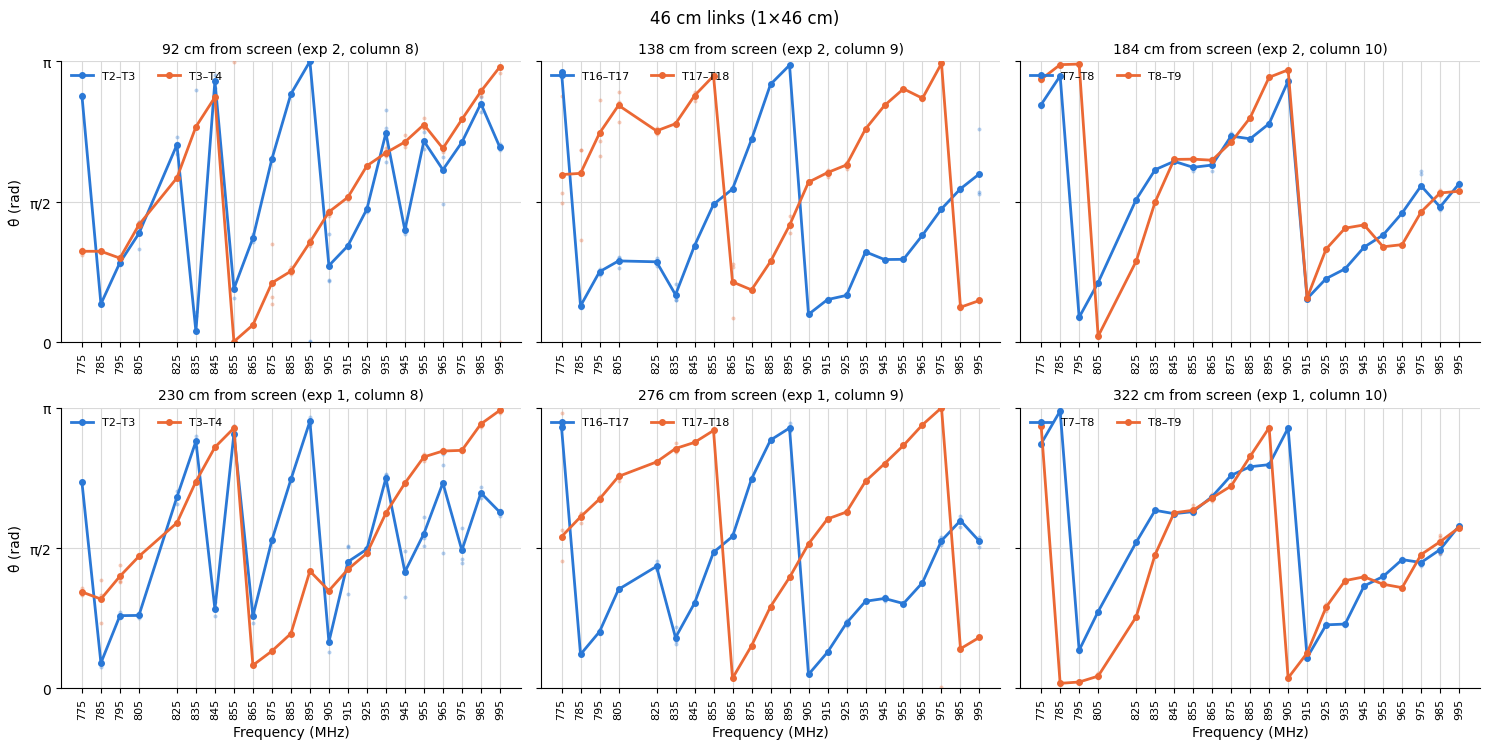

Distances available for link slot (3, 4):
 distance_cm   span exp     where    tags
        92.0  92 cm   2  column 8   T3–T4
       138.0 138 cm   2  column 9 T17–T18
       184.0 184 cm   2 column 10   T8–T9
       230.0 230 cm   1  column 8   T3–T4
       276.0 276 cm   1  column 9 T17–T18
       322.0 322 cm   1 column 10   T8–T9


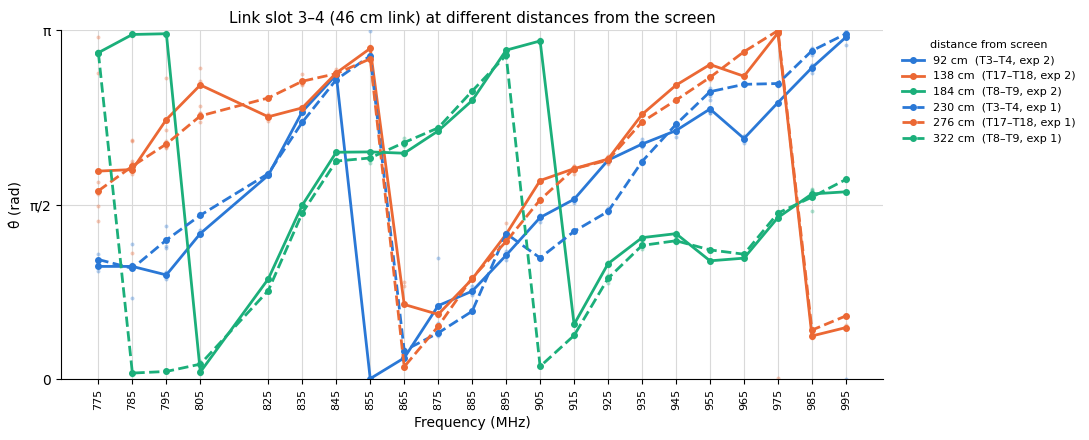

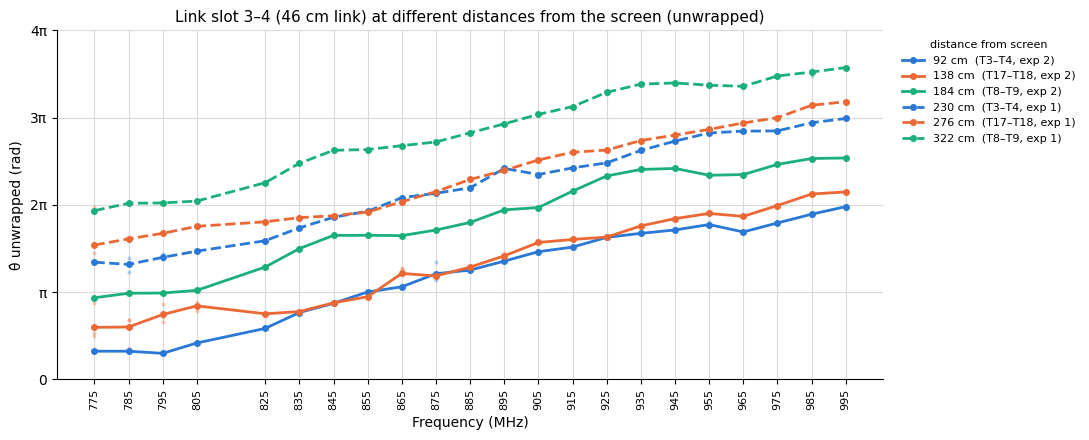

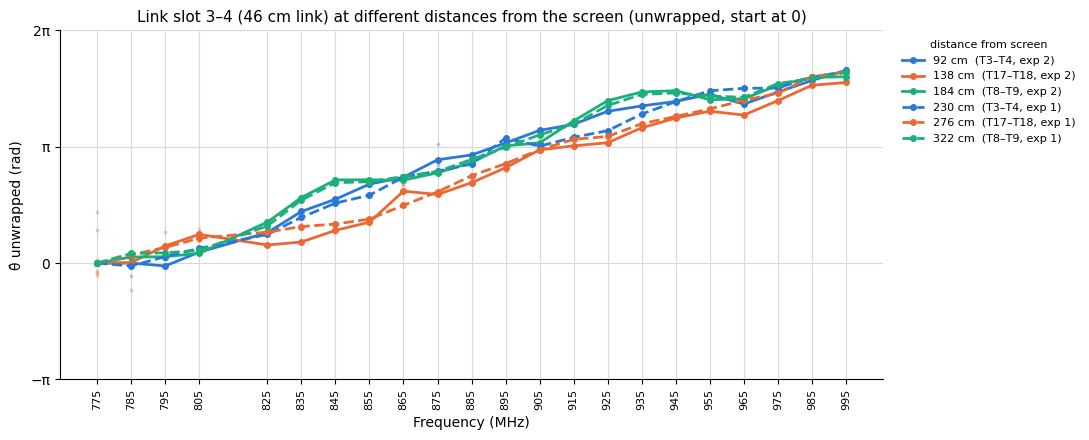

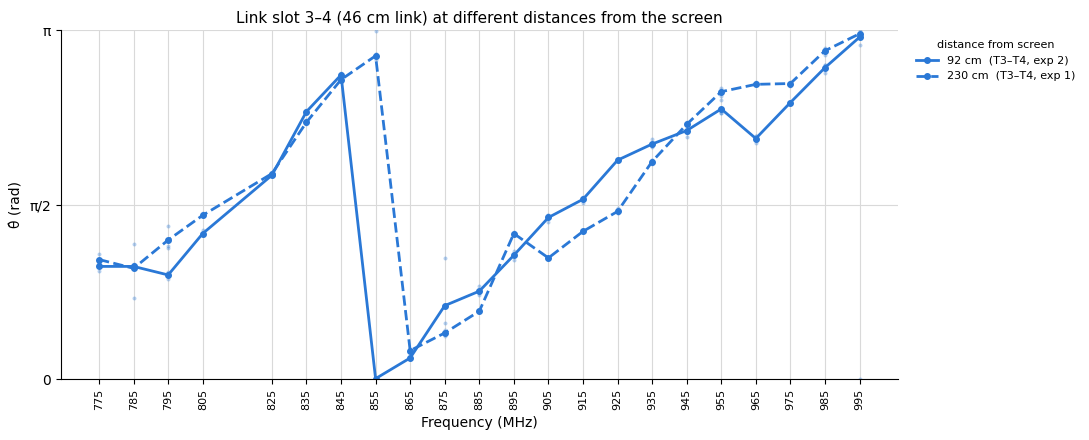

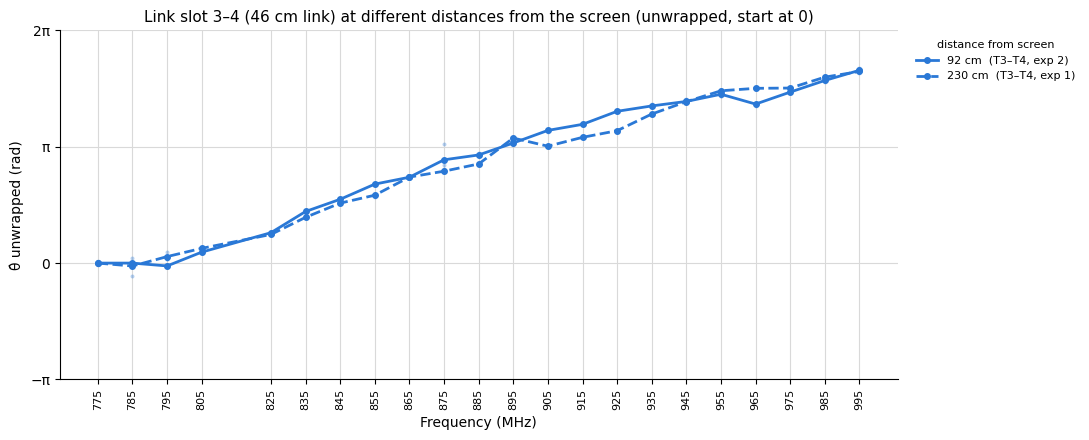

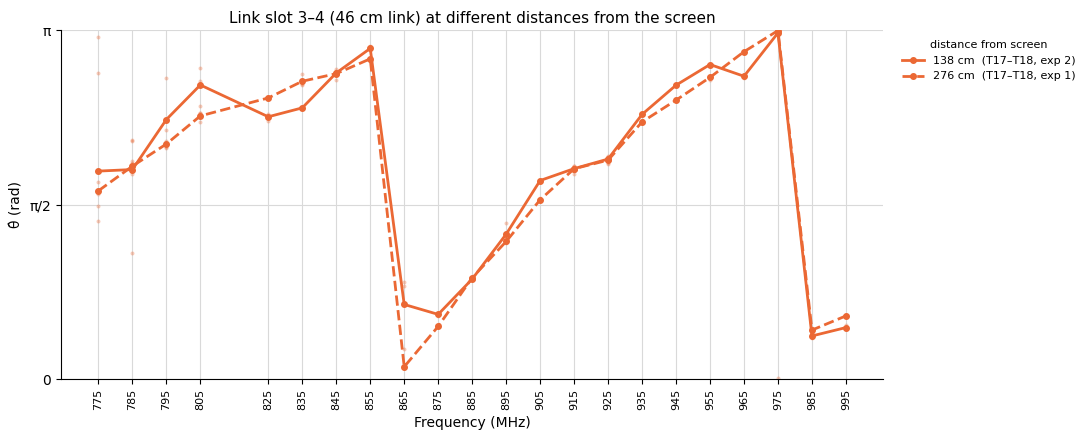

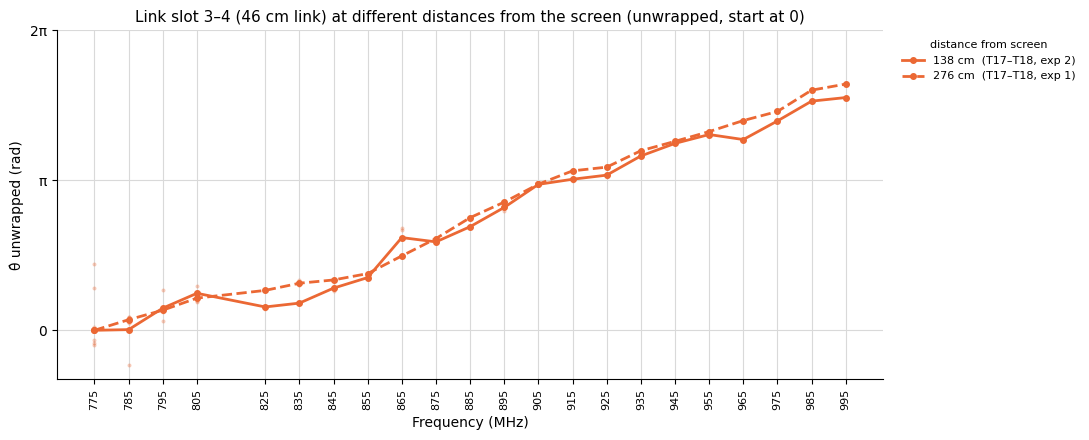

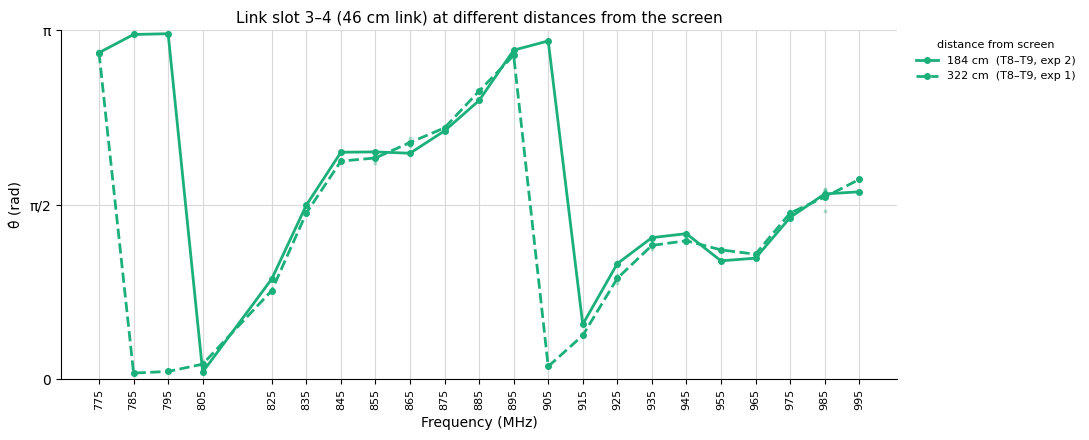

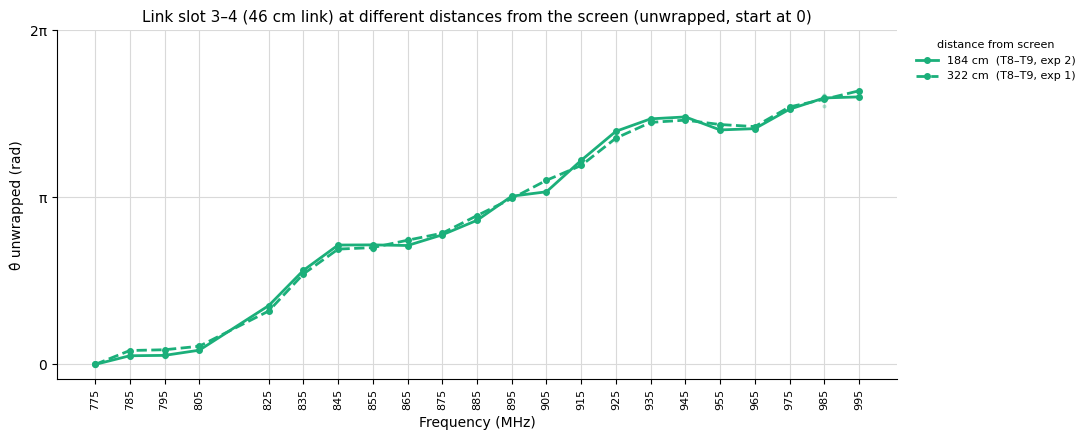

In [150]:
LINKS_46 = [(2, 3), (3, 4)]   # all 46 cm slots: [(1, 2), (2, 3), (3, 4), (4, 5)]
LINK_46 = (3, 4)                  # slot for the link-vs-distance and 3D plots
# DISTANCES_46 = (92, 138, 184)       # cm from screen; None = all
DISTANCES_46 = (92, 138, 184,230, 276, 322)       # cm from screen; None = all
# DISTANCES_46 = (92,230)       # cm from screen; None = all
# DISTANCES_46 = (138, 230, 276)
# DISTANCES_46 = (230, 276, 322)
check_link_length(LINKS_46 + [LINK_46], 46)

plot_link_panels(theta_data, "θ̂ (rad)", agg=circmean_mod_pi,
                 ylim=(0, np.pi), yticks=([0, np.pi / 2, np.pi], ["0", "π/2", "π"]), links=LINKS_46,
                 title="46 cm links (1×46 cm)")

print(f"Distances available for link slot {LINK_46}:")
print(available_distances(LINK_46).to_string(index=False))
plot_link_vs_distance(LINK_46, distances=DISTANCES_46)
plot_link_vs_distance(LINK_46, distances=DISTANCES_46, unwrap=True)
plot_link_vs_distance(LINK_46, distances=DISTANCES_46, unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_46, distances=(92,230))
plot_link_vs_distance(LINK_46, distances=(92,230), unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_46, distances=(138,276))
plot_link_vs_distance(LINK_46, distances=(138,276), unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_46, distances=(184,322))
plot_link_vs_distance(LINK_46, distances=(184,322),unwrap=True, zero_start=True)

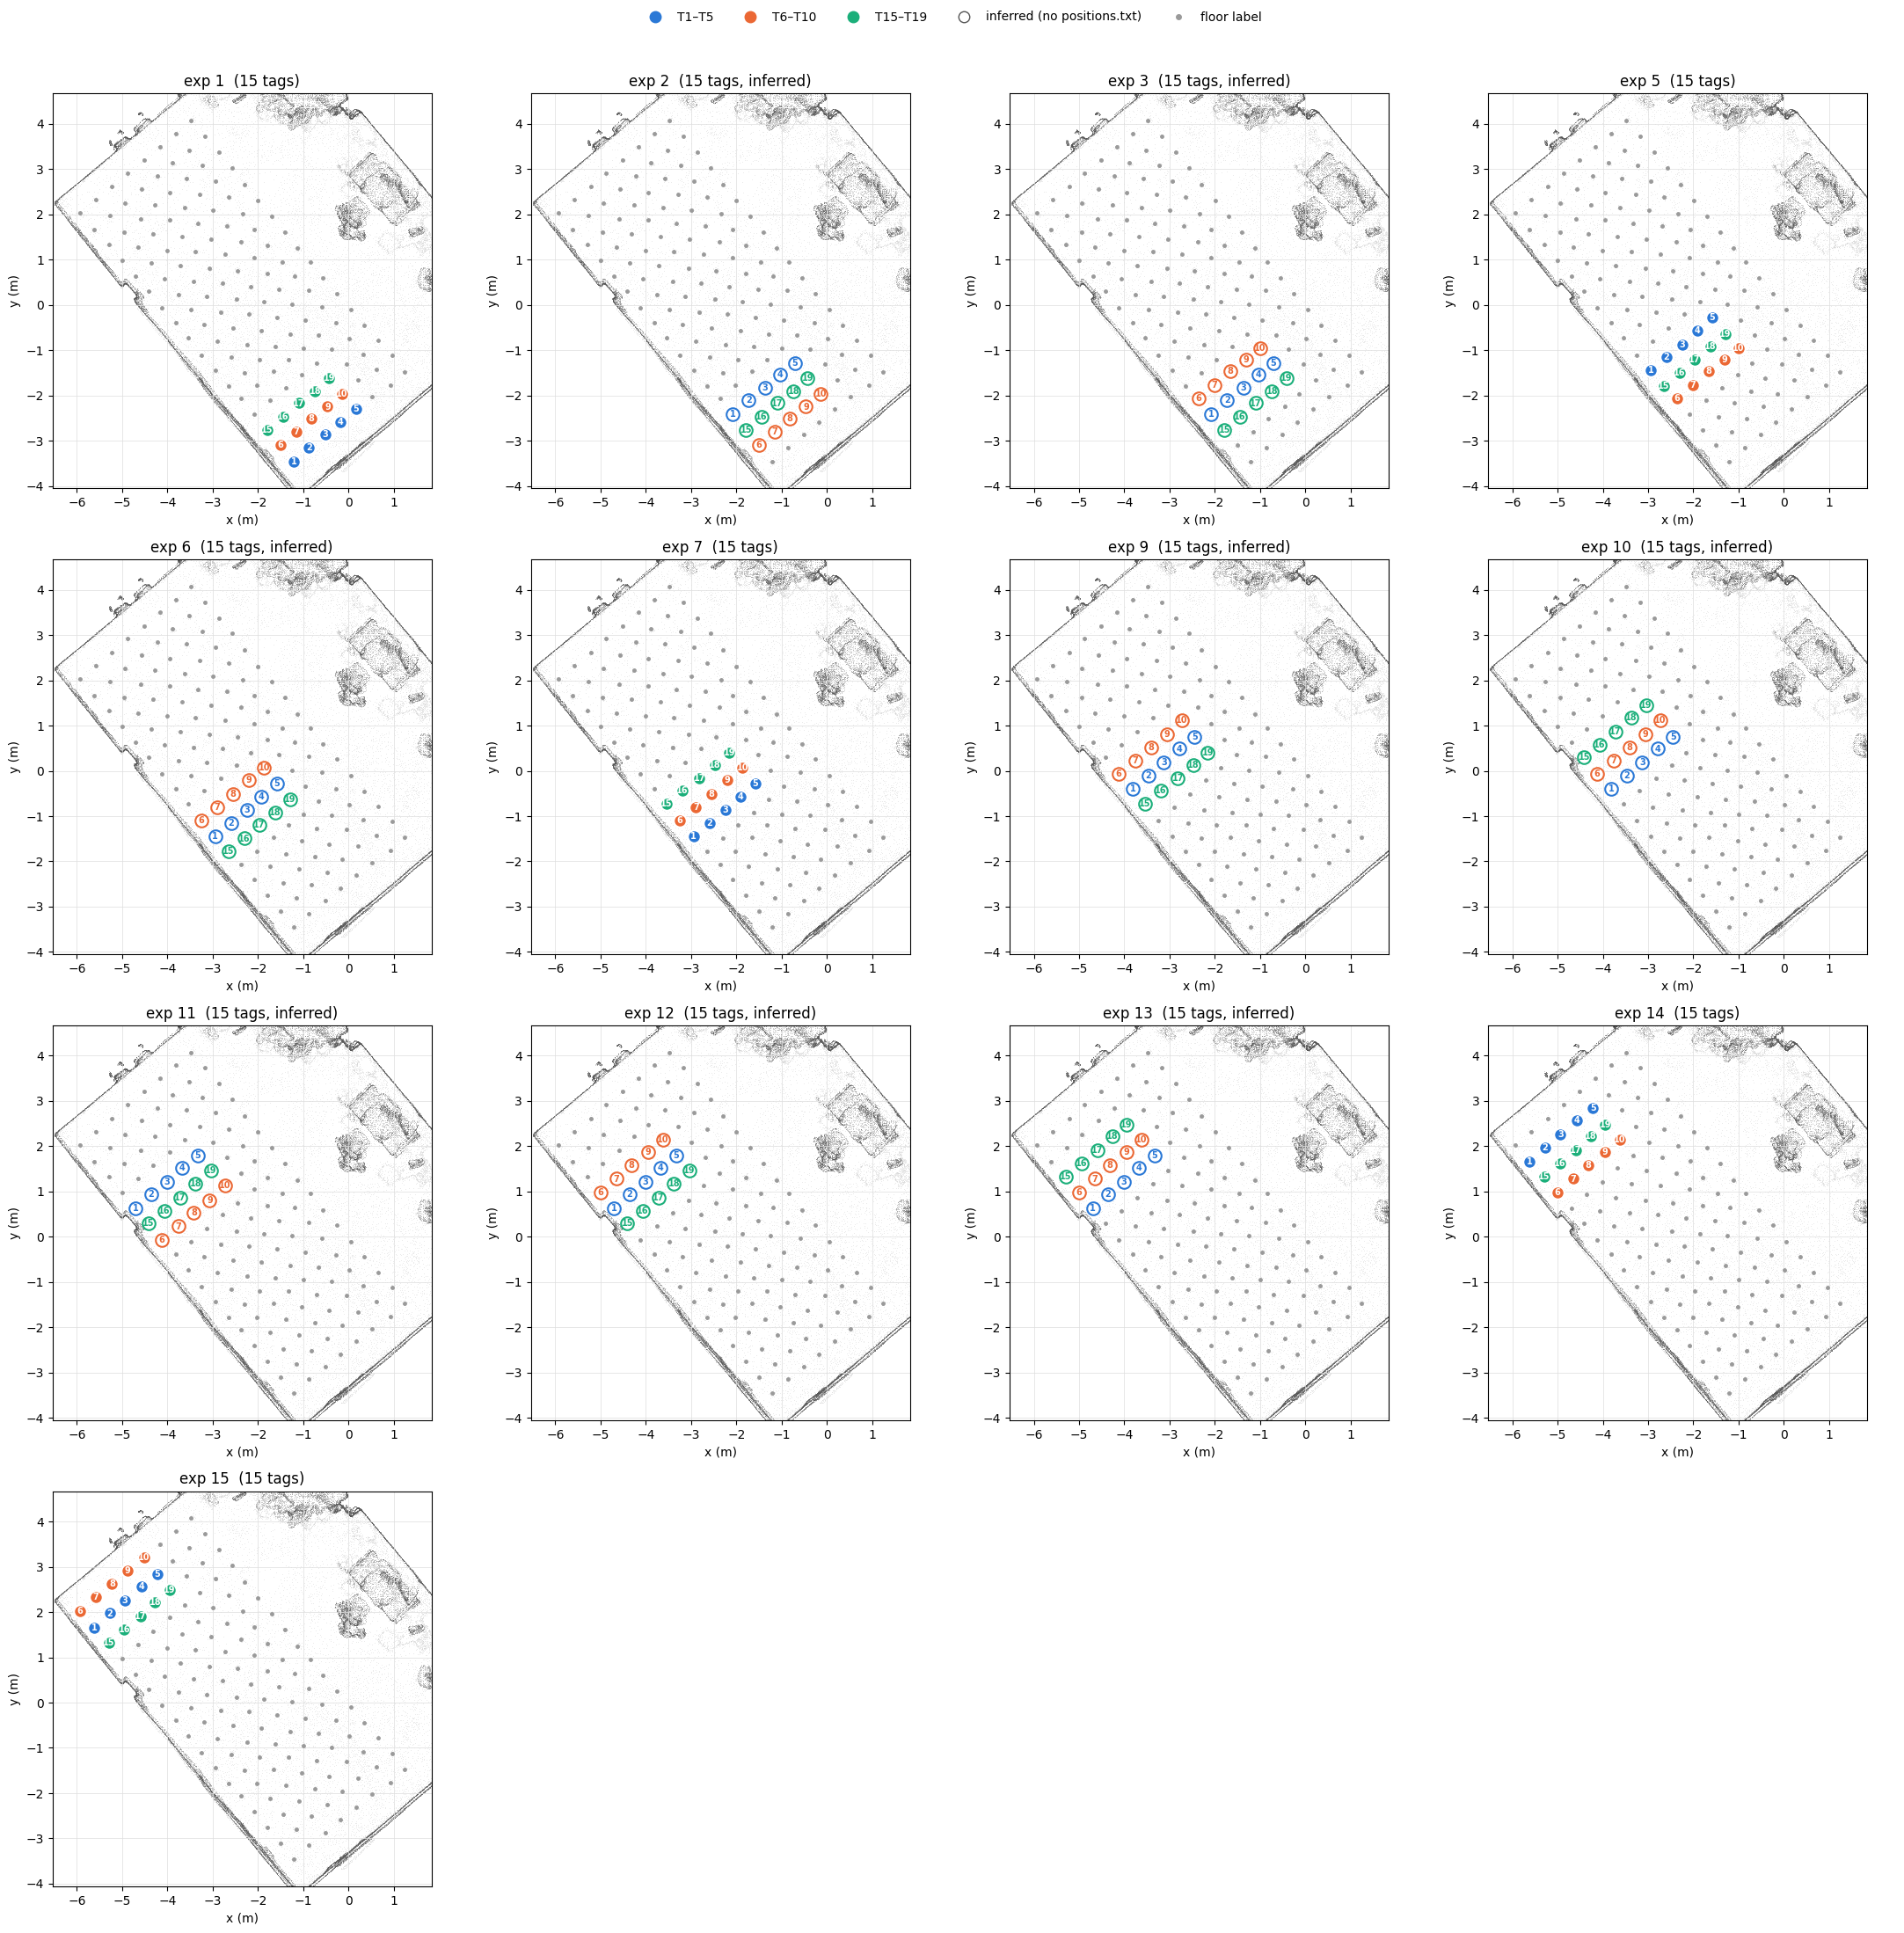

In [ ]:
SHOW_MARKER_LABELS = False   # print every floor label (1–136) in grey
ZOOM = True                  # crop to the marker grid instead of the whole room
N_COLS = 4


def tag_color(tag):
    for color, tags in zip(GROUP_COLORS, TAG_GROUPS.values()):
        if int(tag) in tags:
            return color
    return "#333333"


def plot_experiment_positions(positions, n_cols=N_COLS, zoom=ZOOM, show_marker_labels=SHOW_MARKER_LABELS):
    """One panel per experiment folder. Inferred positions are drawn hollow; folders with no positions are left empty."""
    exps = list(positions)
    n_rows = int(np.ceil(len(exps) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 5.5 * n_rows), squeeze=False)

    for ax, name in zip(axes.flat, exps):
        pos = positions[name]
        draw_room(ax)
        if show_marker_labels:
            for lab, r in markers.iterrows():
                ax.annotate(str(lab), (r.x, r.y), fontsize=5, color="#9a9a9a",
                            xytext=(2, 2), textcoords="offset points")
        if pos is None:
            ax.set_title(f"exp {name}  (no positions.txt)", color="#9a9a9a")
        else:
            inferred = pos["source"].iloc[0] == "inferred"
            for tag, r in pos.iterrows():
                color = tag_color(tag)
                ax.scatter(r.x, r.y, s=110, color="white" if inferred else color,
                           edgecolors=color if inferred else "white", linewidths=1.5, zorder=3)
                ax.annotate(tag, (r.x, r.y), ha="center", va="center", fontsize=7,
                            color=color if inferred else "white", fontweight="bold", zorder=4)
            ax.set_title(f"exp {name}  ({len(pos)} tags{', inferred' if inferred else ''})")
        ax.grid(True, color="#dddddd", lw=0.5)
        if zoom:
            pad = 0.6
            ax.set_xlim(markers["x"].min() - pad, markers["x"].max() + pad)
            ax.set_ylim(markers["y"].min() - pad, markers["y"].max() + pad)

    for ax in axes.flat[len(exps):]:
        ax.axis("off")

    handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=9, label=g)
               for g, c in zip(TAG_GROUPS, GROUP_COLORS)]
    handles.append(plt.Line2D([], [], marker="o", ls="", color="white", markeredgecolor="#555555",
                              markersize=9, label="inferred (no positions.txt)"))
    handles.append(plt.Line2D([], [], marker="o", ls="", color="#9a9a9a", markersize=4, label="floor label"))
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig


plot_experiment_positions(positions)
plt.show()

In [141]:
plot_link_vs_distance_3d(LINK_46, surface=True, unwrap=True)   # distances=DISTANCES_46 to match the 2D plot
plot_link_vs_distance_3d(LINK_46, surface=True, unwrap=True, zero_start=True)


### 46 cm links perpendicular to the wall (1×46 cm across tag columns, e.g. T5–T19, T19–T10)

Same row, tag columns 1 apart (`perp_gap=1`); distance from the screen = link midpoint.

1. **2D per column pair** — `PERP_ROWS_46` = rows to draw in every panel.
2. **2D link vs distance** — row `PERP_ROW_46` at the distances in `PERP_DISTANCES_46` (`None` = all; the table lists what's available).
3. **3D** — row `PERP_ROW_46` at all distances.

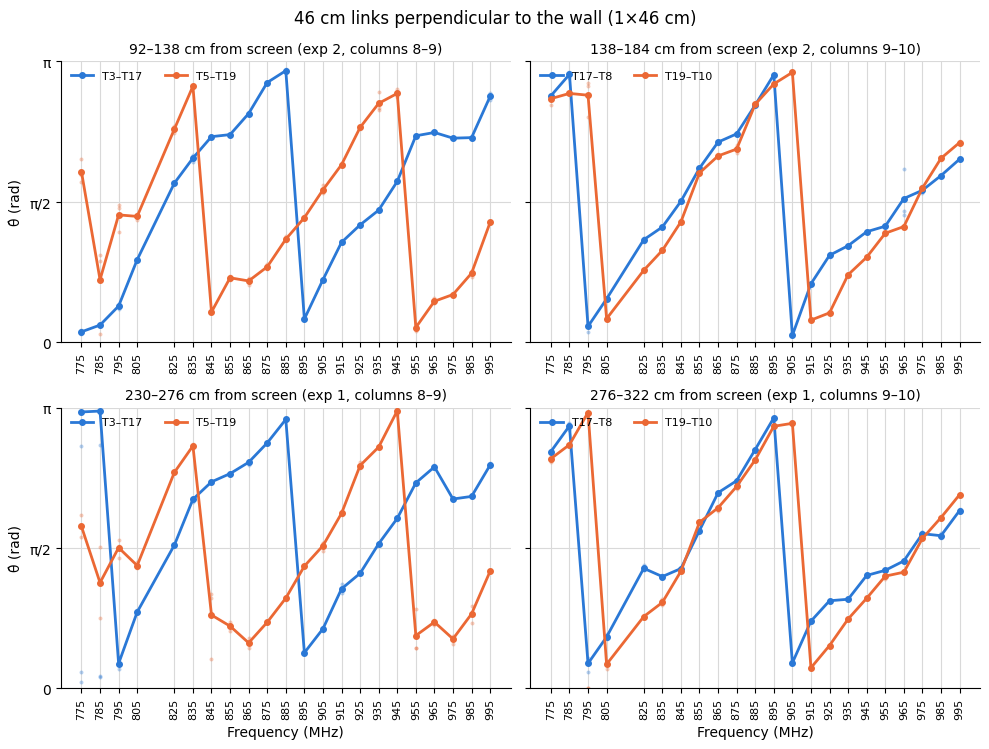

Distances available for perpendicular row 5:
 distance_cm       span exp        where    tags
       115.0  92–138 cm   2  columns 8–9  T5–T19
       161.0 138–184 cm   2 columns 9–10 T19–T10
       253.0 230–276 cm   1  columns 8–9  T5–T19
       299.0 276–322 cm   1 columns 9–10 T19–T10


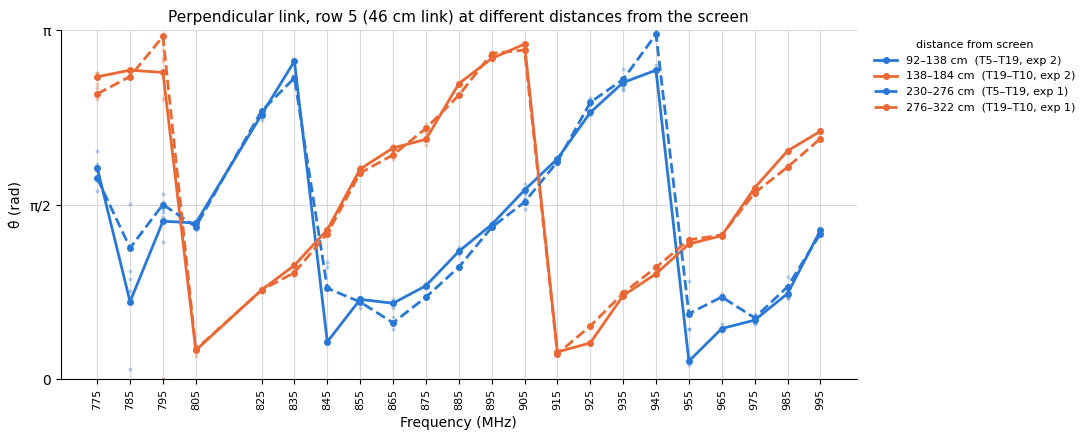

In [142]:
PERP_ROWS_46 = [3, 5]       # rows to draw in every panel; all: [1, 2, 3, 4, 5]
PERP_ROW_46 = 5             # row for the link-vs-distance and 3D plots
PERP_DISTANCES_46 = None    # cm from screen (link midpoint); None = all

plot_link_panels(theta_data, "θ̂ (rad)", agg=circmean_mod_pi,
                 ylim=(0, np.pi), yticks=([0, np.pi / 2, np.pi], ["0", "π/2", "π"]),
                 links=PERP_ROWS_46, perp_gap=1, n_cols=2,
                 title="46 cm links perpendicular to the wall (1×46 cm)")

print(f"Distances available for perpendicular row {PERP_ROW_46}:")
print(available_distances(PERP_ROW_46, perp_gap=1).to_string(index=False))
plot_link_vs_distance(PERP_ROW_46, distances=PERP_DISTANCES_46, perp_gap=1)

In [143]:
plot_link_vs_distance_3d(PERP_ROW_46, perp_gap=1, surface=True)   # distances=PERP_DISTANCES_46 to match the 2D plot
plot_link_vs_distance_3d(PERP_ROW_46, perp_gap=1, surface=True, unwrap=True, zero_start=True)


## 92 cm links (2×46 cm: tags 2 rows apart, e.g. T1–T3, T2–T4, T3–T5)

1. **2D per tag column** — `LINKS_92` = slots to draw in every panel.
2. **2D link vs distance** — slot `LINK_92` at the distances in `DISTANCES_92` (`None` = all; the table lists what's available).
3. **3D** — slot `LINK_92` at all distances.

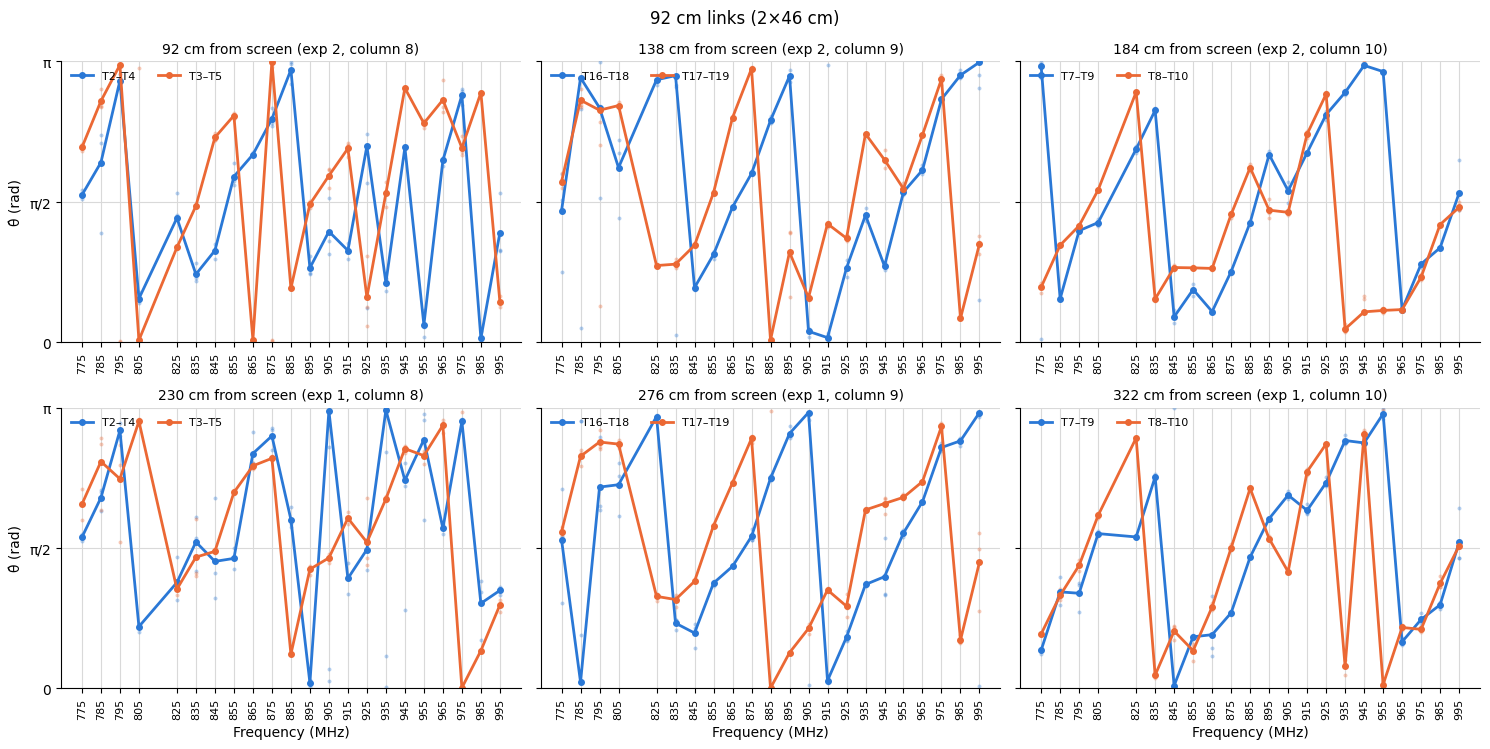

Distances available for link slot (2, 4):
 distance_cm   span exp     where    tags
        92.0  92 cm   2  column 8   T2–T4
       138.0 138 cm   2  column 9 T16–T18
       184.0 184 cm   2 column 10   T7–T9
       230.0 230 cm   1  column 8   T2–T4
       276.0 276 cm   1  column 9 T16–T18
       322.0 322 cm   1 column 10   T7–T9


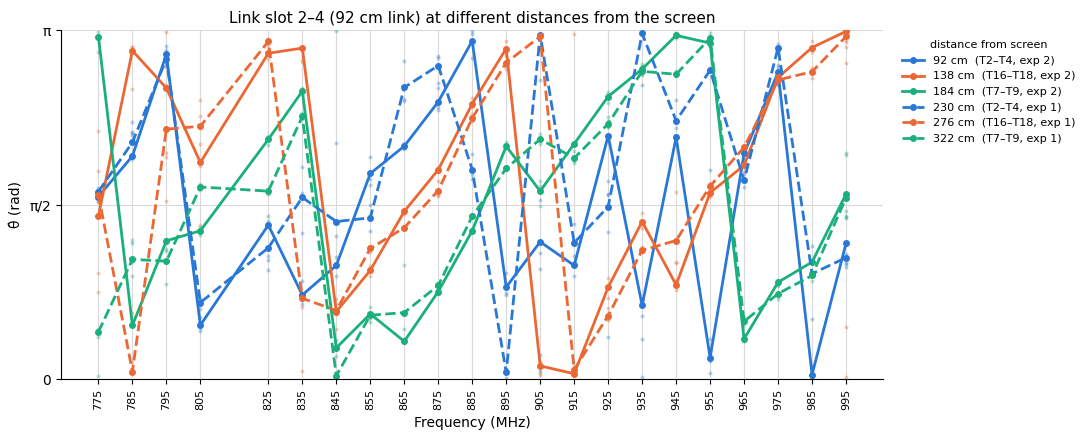

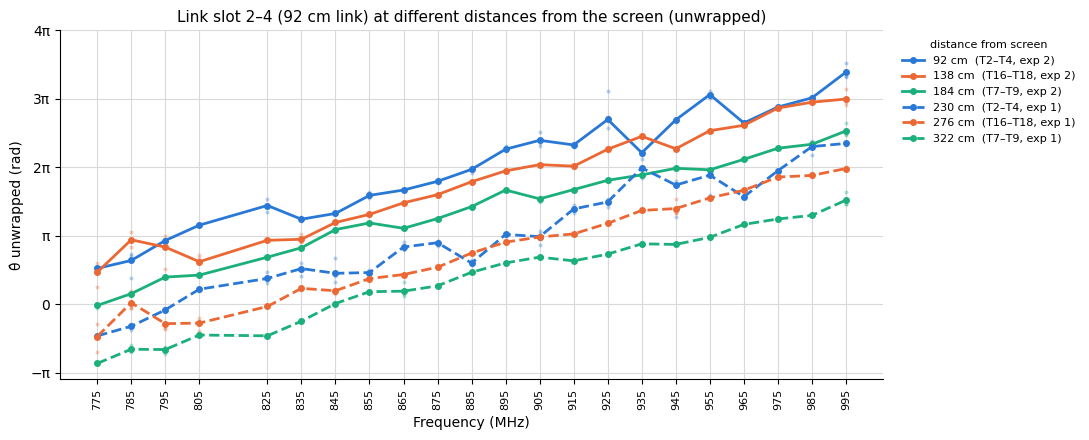

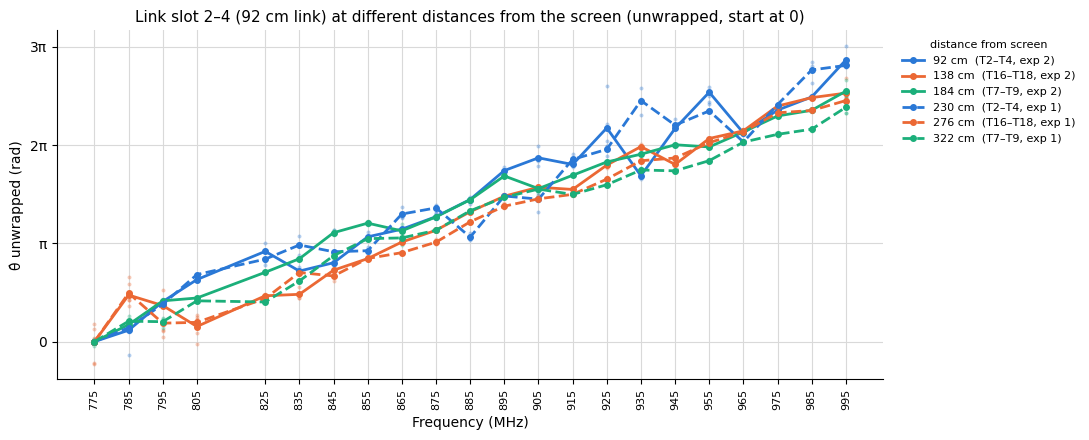

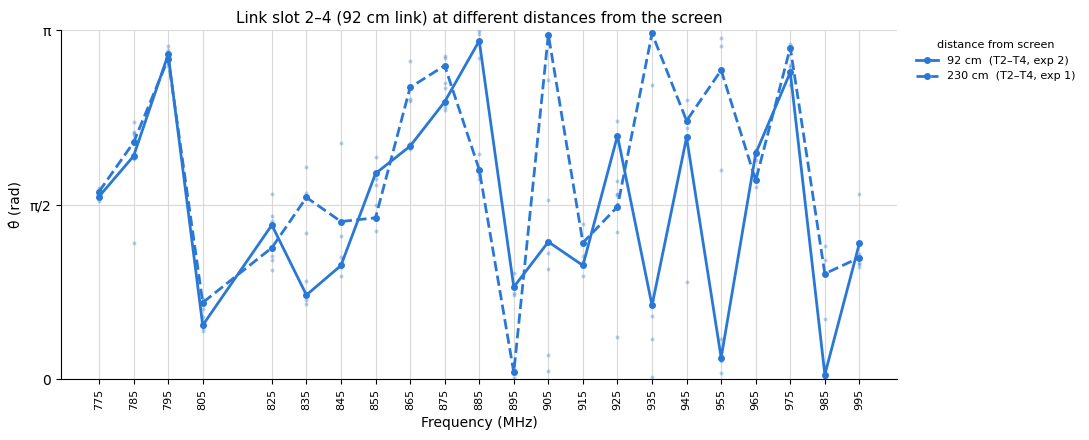

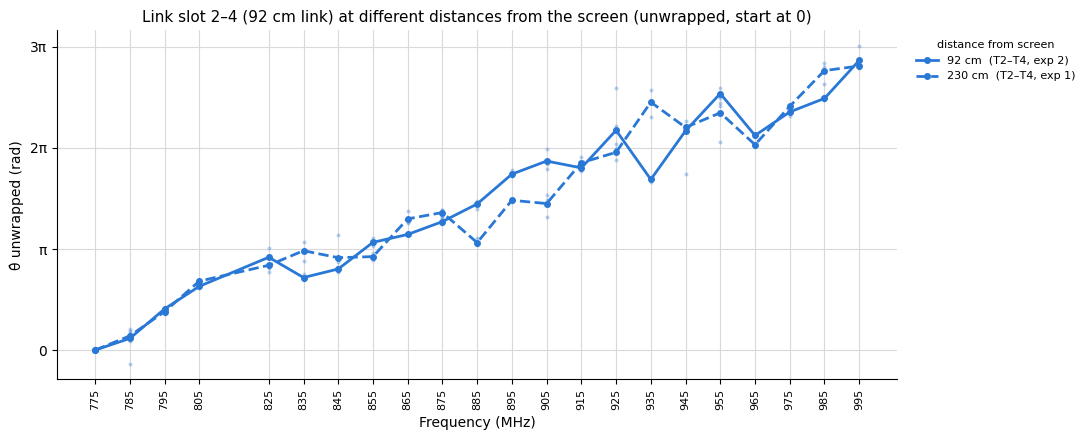

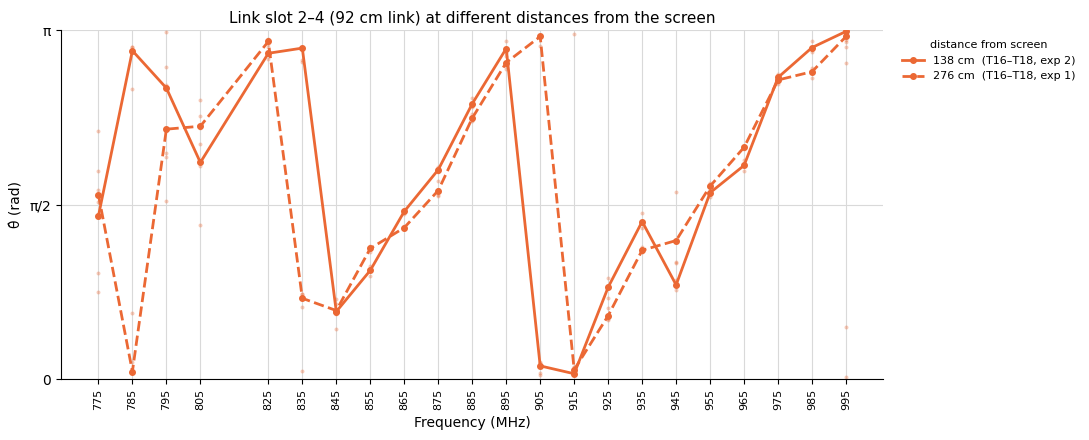

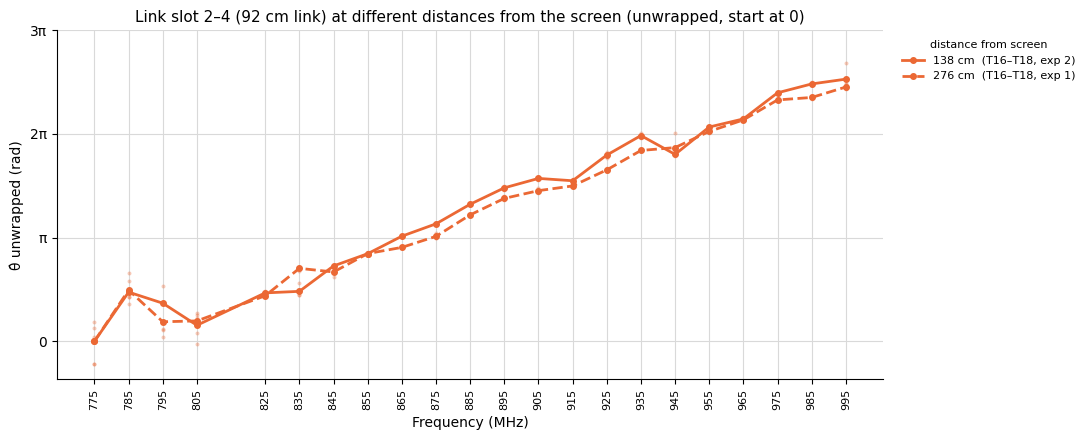

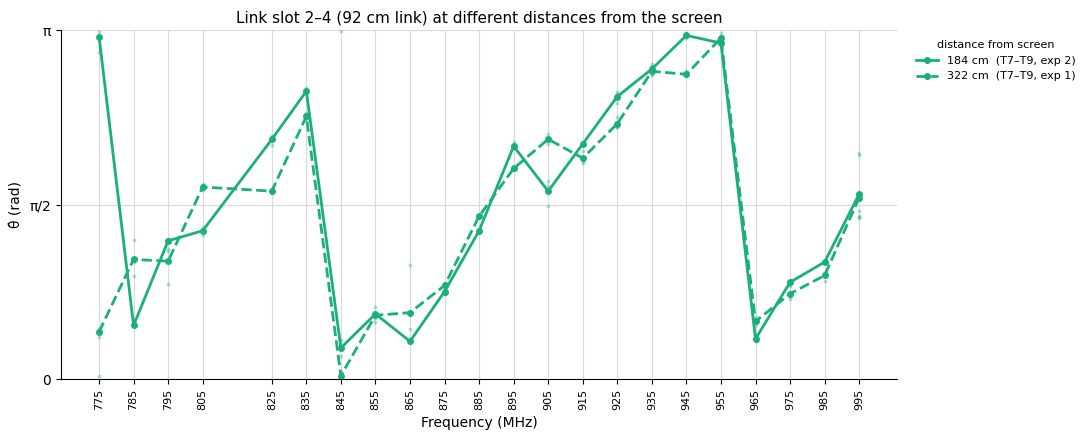

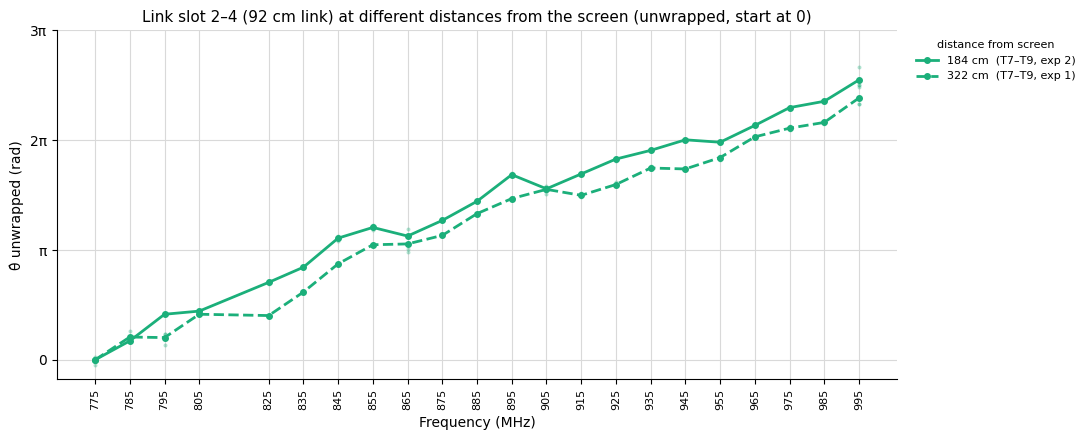

In [151]:
# LINKS_92 = [(1, 3), (2, 4), (3, 5)]   # all 92 cm slots: [(1, 3), (2, 4), (3, 5)]
LINKS_92 = [(2, 4),(3,5)]   # all 92 cm slots: [(1, 3), (2, 4), (3, 5)]
LINK_92 = (2, 4)                  # slot for the link-vs-distance and 3D plots
DISTANCES_92 = None       # cm from screen; None = all
check_link_length(LINKS_92 + [LINK_92], 92)

plot_link_panels(theta_data, "θ̂ (rad)", agg=circmean_mod_pi,
                 ylim=(0, np.pi), yticks=([0, np.pi / 2, np.pi], ["0", "π/2", "π"]), links=LINKS_92,
                 title="92 cm links (2×46 cm)")

print(f"Distances available for link slot {LINK_92}:")
print(available_distances(LINK_92).to_string(index=False),)
plot_link_vs_distance(LINK_92, distances=DISTANCES_92, unwrap=False)
plot_link_vs_distance(LINK_92, distances=DISTANCES_92, unwrap=True)
plot_link_vs_distance(LINK_92, distances=DISTANCES_92, unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_92, distances=(92,230))
plot_link_vs_distance(LINK_92, distances=(92,230), unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_92, distances=(138,276))
plot_link_vs_distance(LINK_92, distances=(138,276), unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_92, distances=(184,322))
plot_link_vs_distance(LINK_92, distances=(184,322), unwrap=True, zero_start=True)

In [145]:
plot_link_vs_distance_3d(LINK_92, surface=True, unwrap=True)   # distances=DISTANCES_92 to match the 2D plot
plot_link_vs_distance_3d(LINK_92, surface=True, unwrap=True, zero_start=True)


### 92 cm links perpendicular to the wall (2×46 cm across tag columns, e.g. T5–T10, T1–T6)

Same row, tag columns 2 apart (`perp_gap=2`); distance from the screen = link midpoint.

1. **2D per column pair** — `PERP_ROWS_92` = rows to draw in every panel.
2. **2D link vs distance** — row `PERP_ROW_92` at the distances in `PERP_DISTANCES_92` (`None` = all; the table lists what's available).
3. **3D** — row `PERP_ROW_92` at all distances.

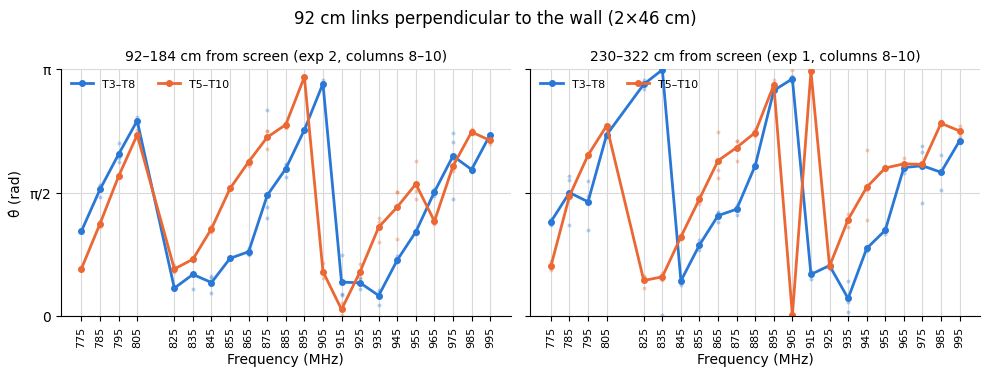

Distances available for perpendicular row 5:
 distance_cm       span exp        where   tags
       138.0  92–184 cm   2 columns 8–10 T5–T10
       276.0 230–322 cm   1 columns 8–10 T5–T10


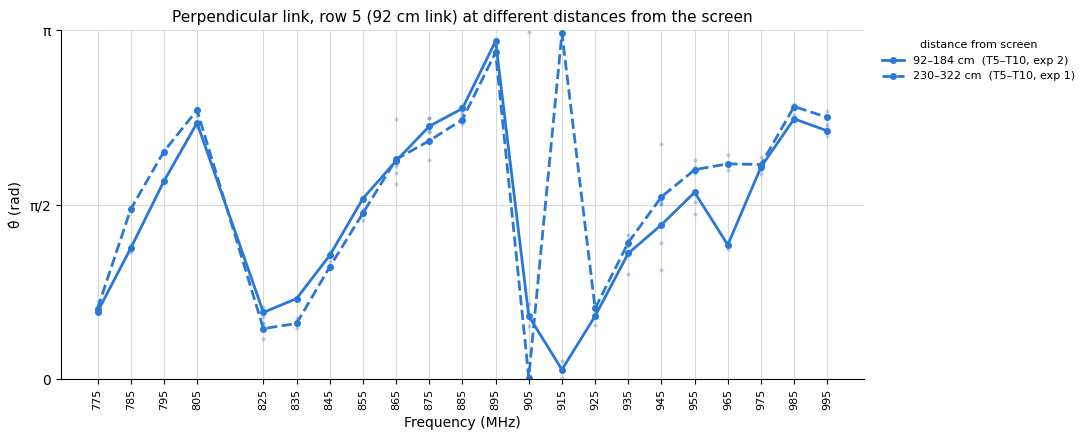

In [146]:
PERP_ROWS_92 = [3, 5]       # rows to draw in every panel; all: [1, 2, 3, 4, 5]
PERP_ROW_92 = 5             # row for the link-vs-distance and 3D plots
PERP_DISTANCES_92 = None    # cm from screen (link midpoint); None = all

plot_link_panels(theta_data, "θ̂ (rad)", agg=circmean_mod_pi,
                 ylim=(0, np.pi), yticks=([0, np.pi / 2, np.pi], ["0", "π/2", "π"]),
                 links=PERP_ROWS_92, perp_gap=2, n_cols=2,
                 title="92 cm links perpendicular to the wall (2×46 cm)")

print(f"Distances available for perpendicular row {PERP_ROW_92}:")
print(available_distances(PERP_ROW_92, perp_gap=2).to_string(index=False))
plot_link_vs_distance(PERP_ROW_92, distances=PERP_DISTANCES_92, perp_gap=2)

In [147]:
plot_link_vs_distance_3d(PERP_ROW_92, perp_gap=2, surface=True, unwrap=True)   # distances=PERP_DISTANCES_92 to match the 2D plot
plot_link_vs_distance_3d(PERP_ROW_92, perp_gap=2, surface=True, unwrap=True, zero_start=True)


## 138 cm links (3×46 cm: tags 3 rows apart, e.g. T1–T4, T2–T5)

1. **2D per tag column** — `LINKS_138` = slots to draw in every panel.
2. **2D link vs distance** — slot `LINK_138` at the distances in `DISTANCES_138` (`None` = all; the table lists what's available).
3. **3D** — slot `LINK_138` at all distances.

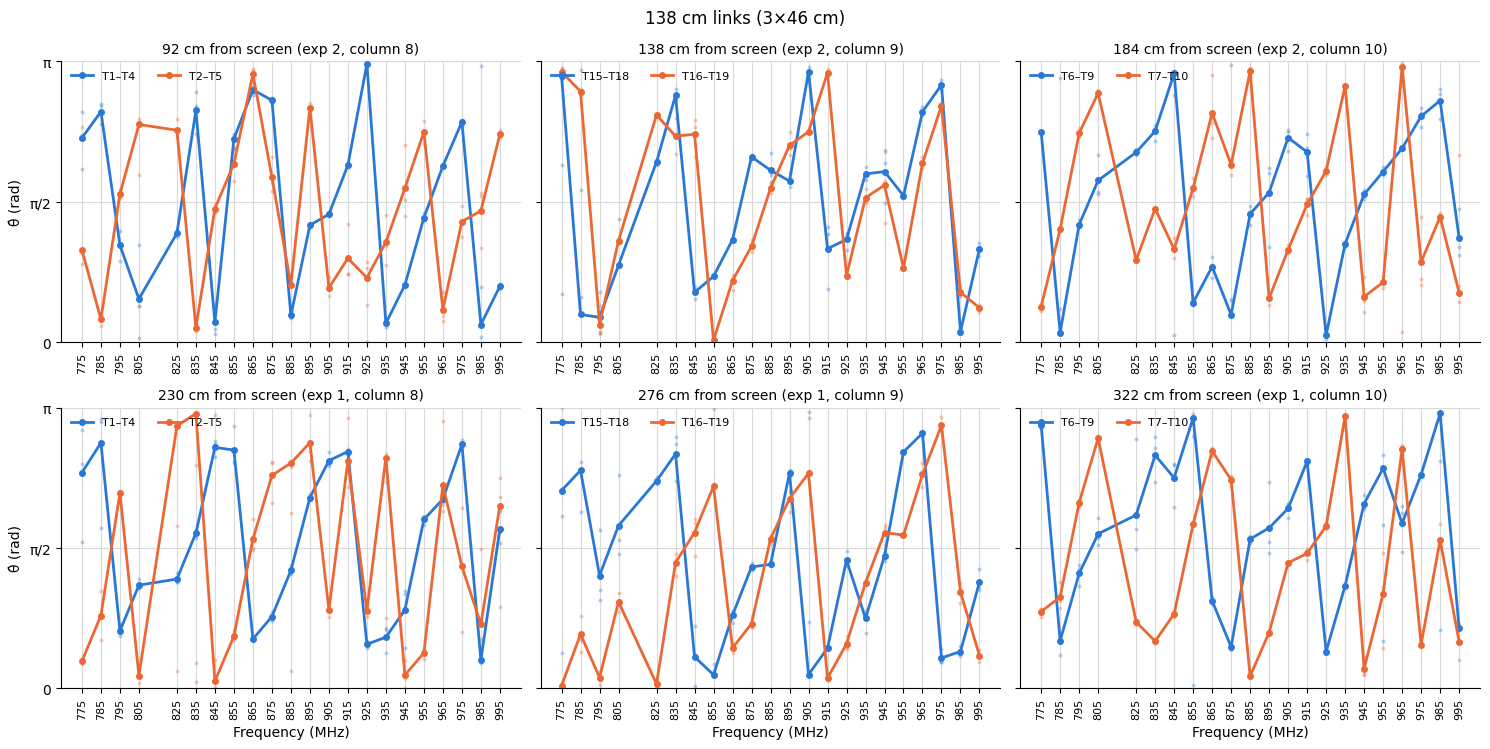

Distances available for link slot (1, 4):
 distance_cm   span exp     where    tags
        92.0  92 cm   2  column 8   T1–T4
       138.0 138 cm   2  column 9 T15–T18
       184.0 184 cm   2 column 10   T6–T9
       230.0 230 cm   1  column 8   T1–T4
       276.0 276 cm   1  column 9 T15–T18
       322.0 322 cm   1 column 10   T6–T9


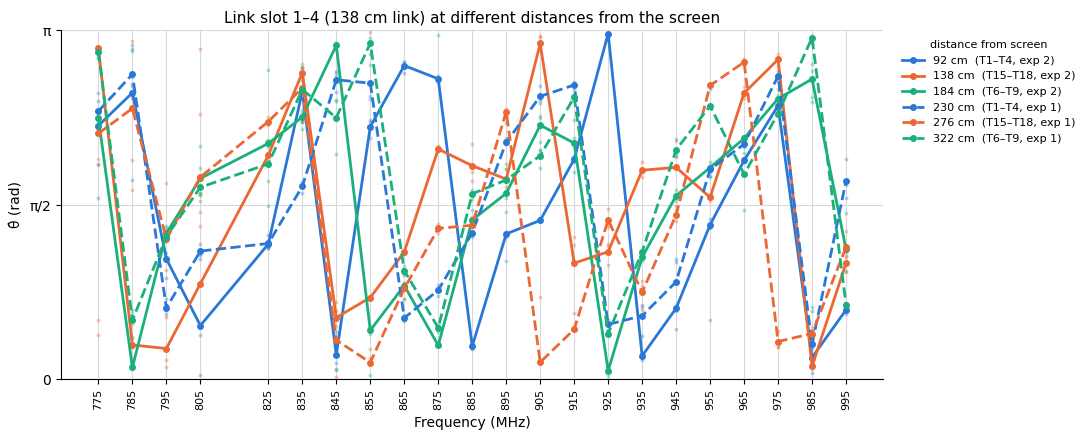

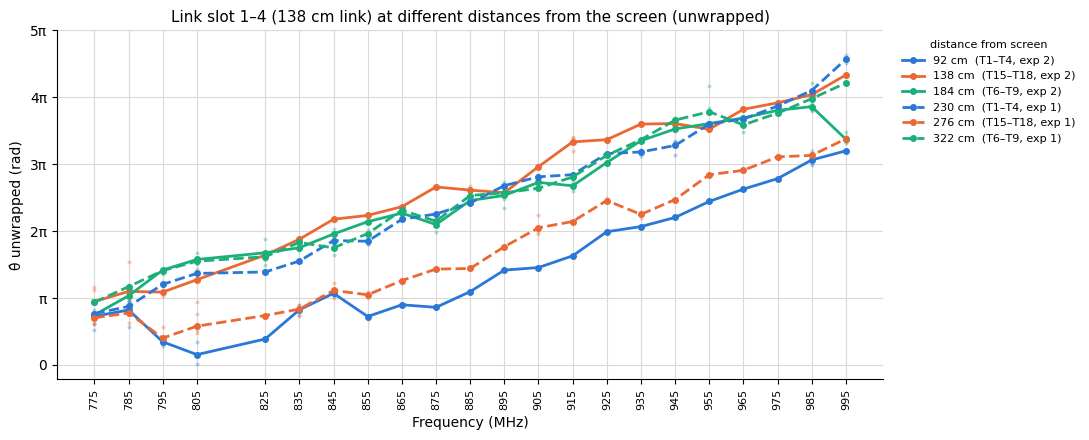

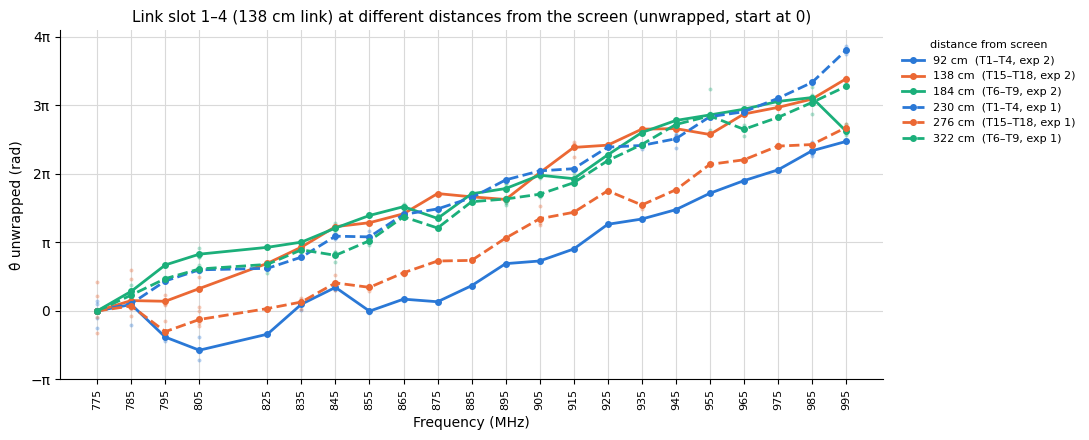

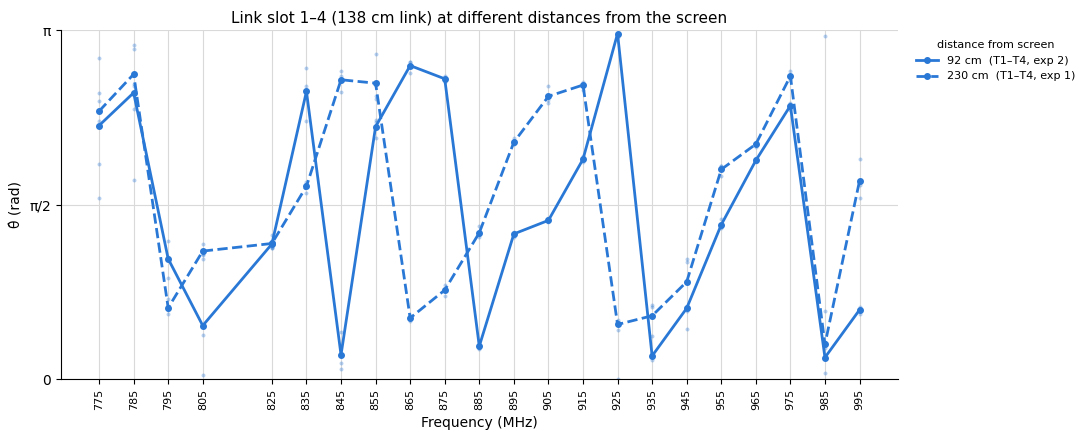

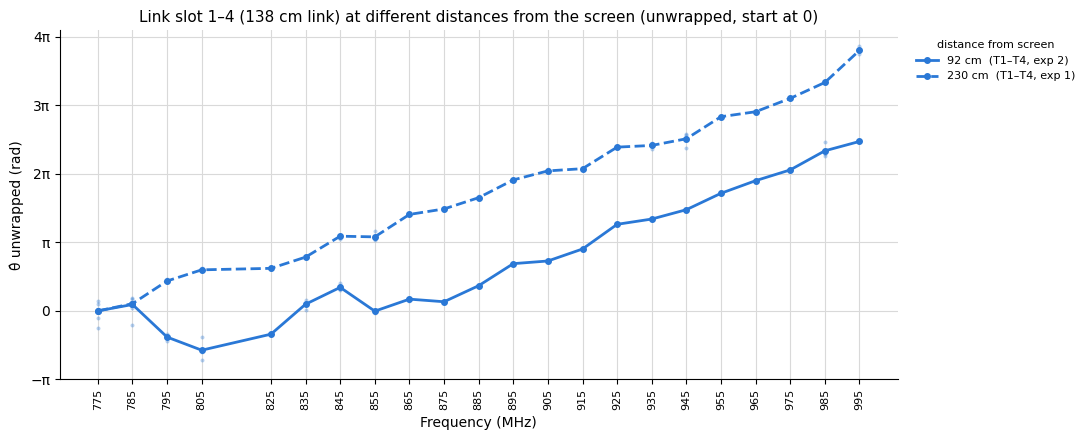

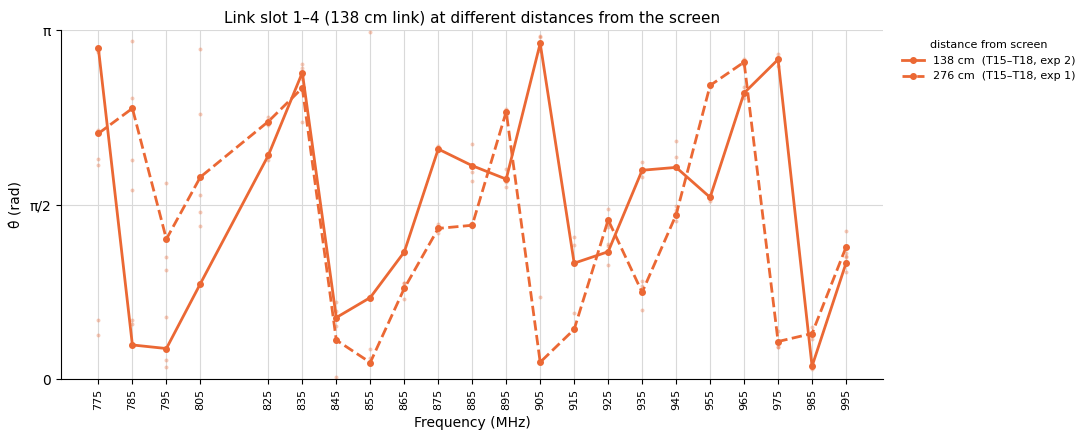

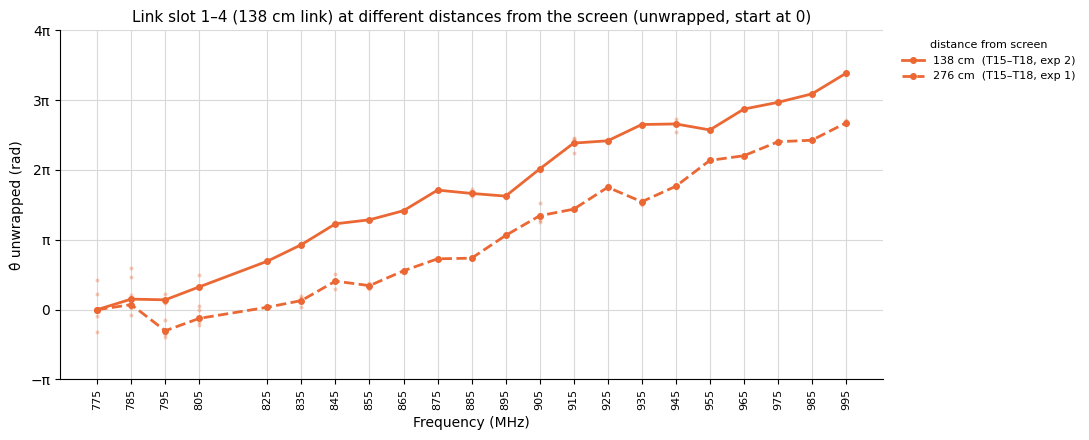

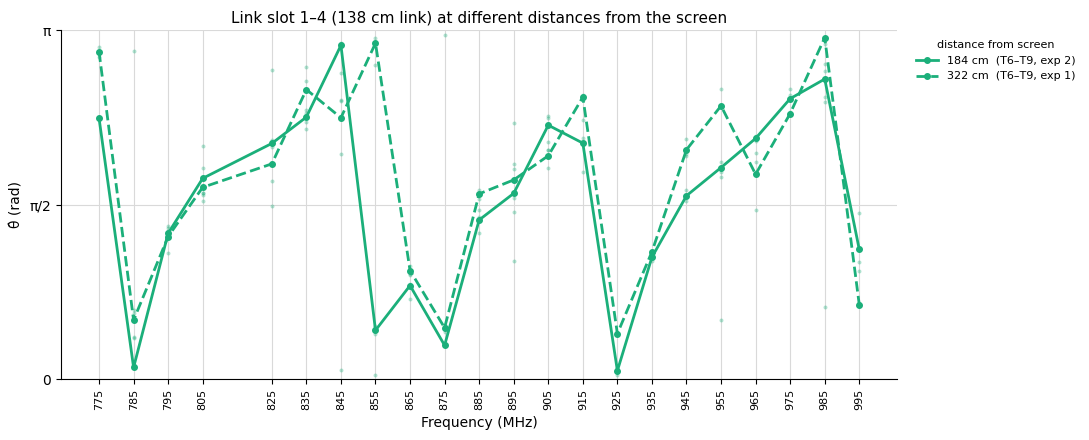

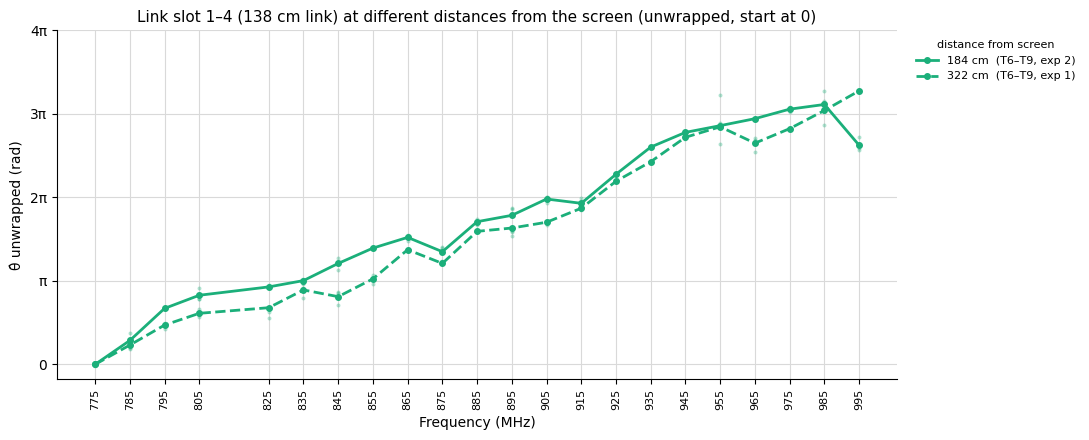

In [152]:
LINKS_138 = [(1, 4), (2, 5)]   # all 138 cm slots: [(1, 4), (2, 5)]
# LINKS_138 = [(1, 4)]   # all 138 cm slots: [(1, 4), (2, 5)]
LINK_138 = (1, 4)                  # slot for the link-vs-distance and 3D plots
DISTANCES_138 = None       # cm from screen; None = all
check_link_length(LINKS_138 + [LINK_138], 138)

plot_link_panels(theta_data, "θ̂ (rad)", agg=circmean_mod_pi,
                 ylim=(0, np.pi), yticks=([0, np.pi / 2, np.pi], ["0", "π/2", "π"]), links=LINKS_138,
                 title="138 cm links (3×46 cm)")

print(f"Distances available for link slot {LINK_138}:")
print(available_distances(LINK_138).to_string(index=False))
plot_link_vs_distance(LINK_138, distances=DISTANCES_138)
plot_link_vs_distance(LINK_138, distances=DISTANCES_138, unwrap=True)
plot_link_vs_distance(LINK_138, distances=DISTANCES_138, unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_138, distances=(92,230))
plot_link_vs_distance(LINK_138, distances=(92,230), unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_138, distances=(138,276))
plot_link_vs_distance(LINK_138, distances=(138,276), unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_138, distances=(184,322))
plot_link_vs_distance(LINK_138, distances=(184,322), unwrap=True, zero_start=True)


In [149]:
plot_link_vs_distance_3d(LINK_138, surface=True, unwrap=True)   # distances=DISTANCES_138 to match the 2D plot
plot_link_vs_distance_3d(LINK_138, surface=True, unwrap=True, zero_start=True)


## 184 cm links (4×46 cm: tags 4 rows apart, i.e. T1–T5)

1. **2D per tag column** — `LINKS_184` = slots to draw in every panel (only `(1, 5)` exists).
2. **2D link vs distance** — slot `LINK_184` at the distances in `DISTANCES_184` (`None` = all; the table lists what's available).
3. **3D** — slot `LINK_184` at all distances.


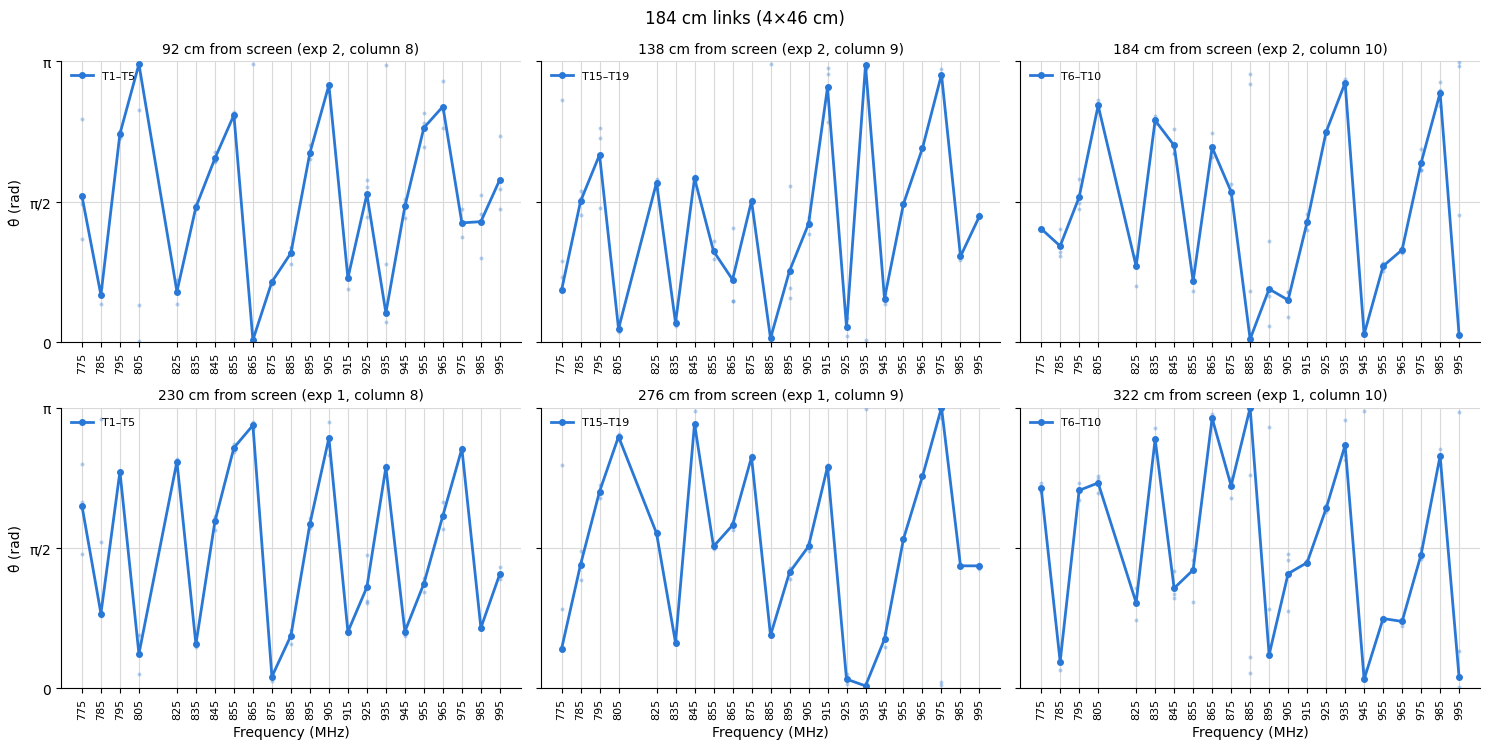

Distances available for link slot (1, 5):
 distance_cm   span exp     where    tags
        92.0  92 cm   2  column 8   T1–T5
       138.0 138 cm   2  column 9 T15–T19
       184.0 184 cm   2 column 10  T6–T10
       230.0 230 cm   1  column 8   T1–T5
       276.0 276 cm   1  column 9 T15–T19
       322.0 322 cm   1 column 10  T6–T10


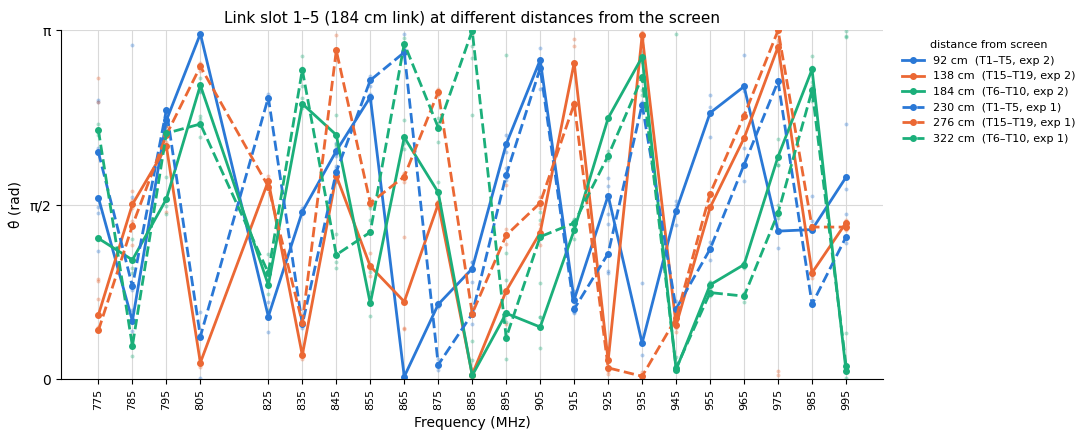

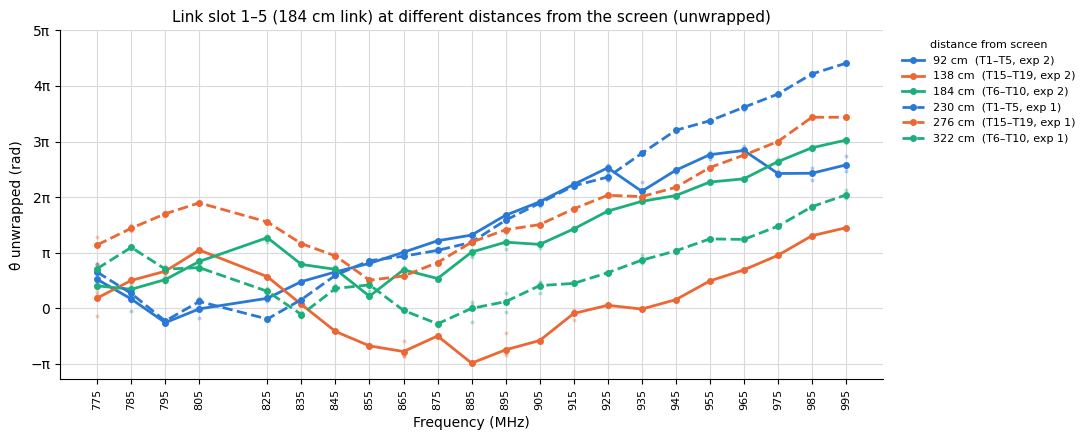

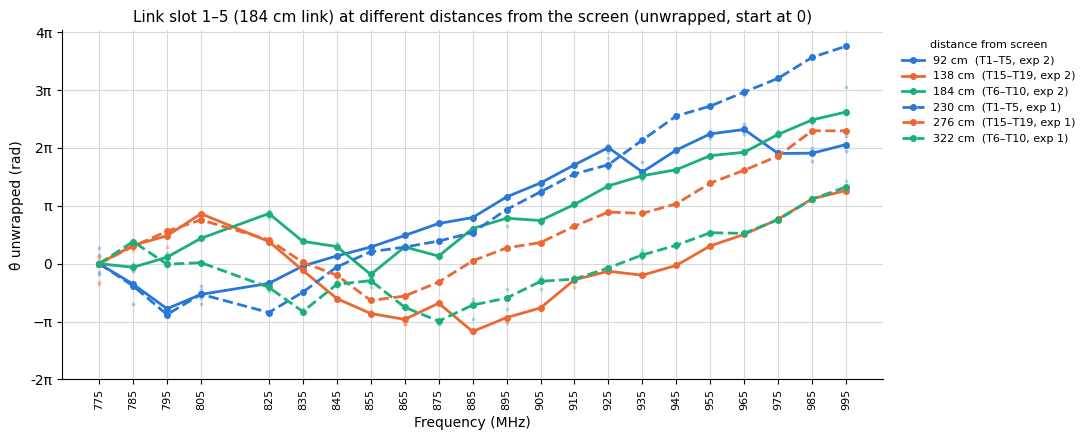

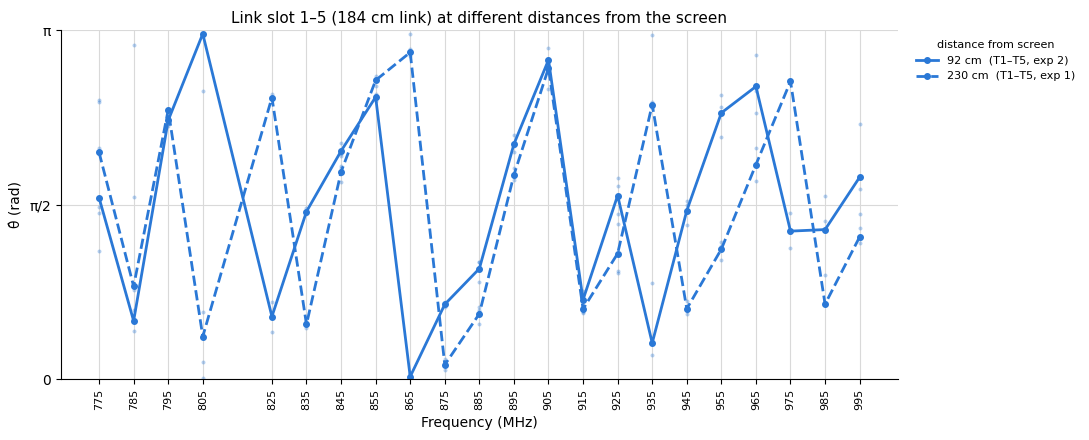

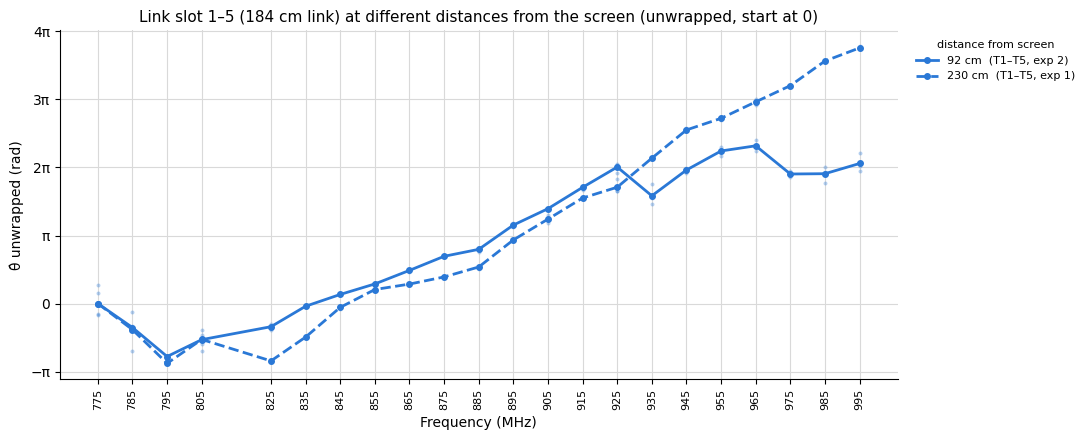

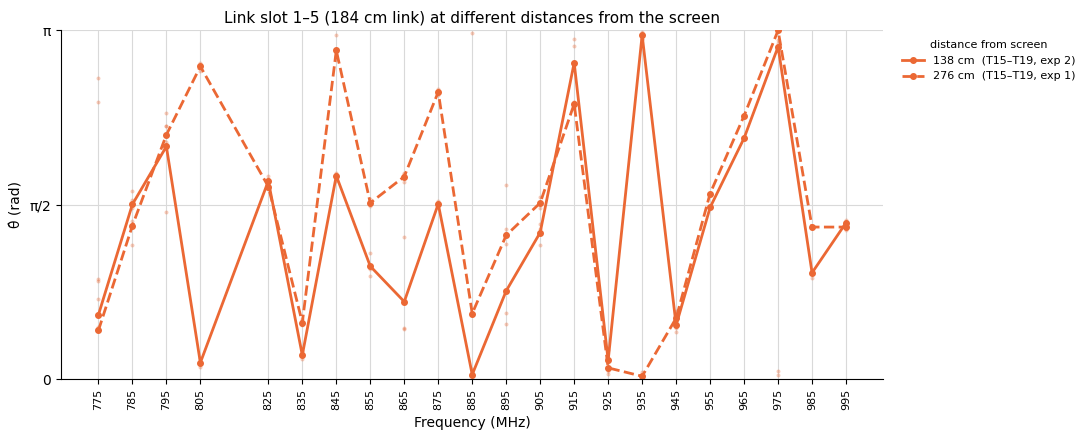

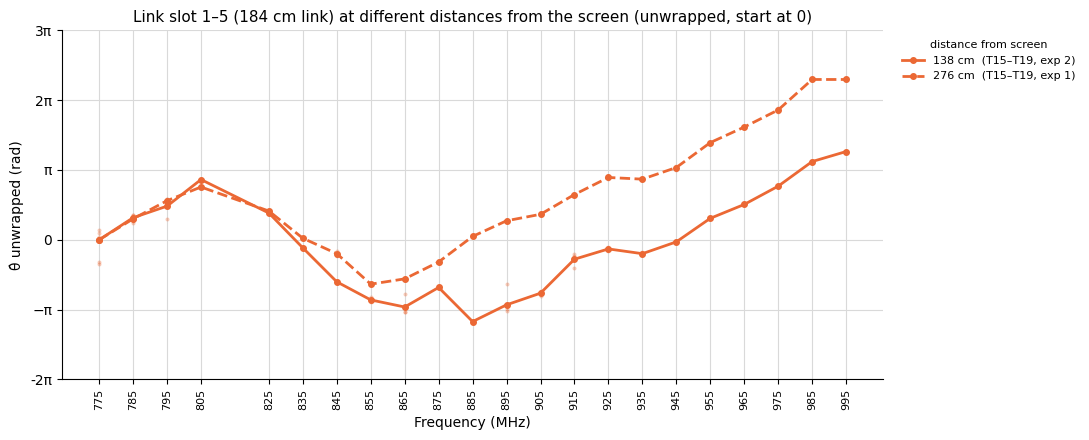

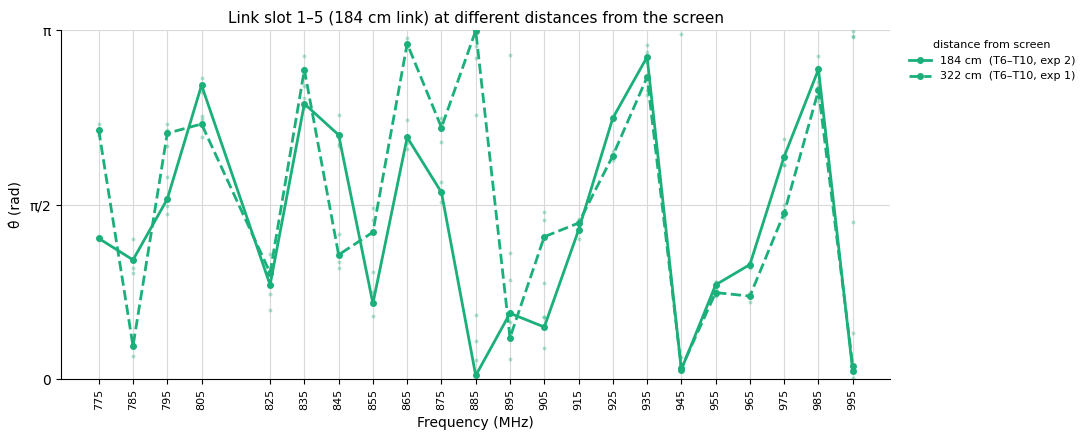

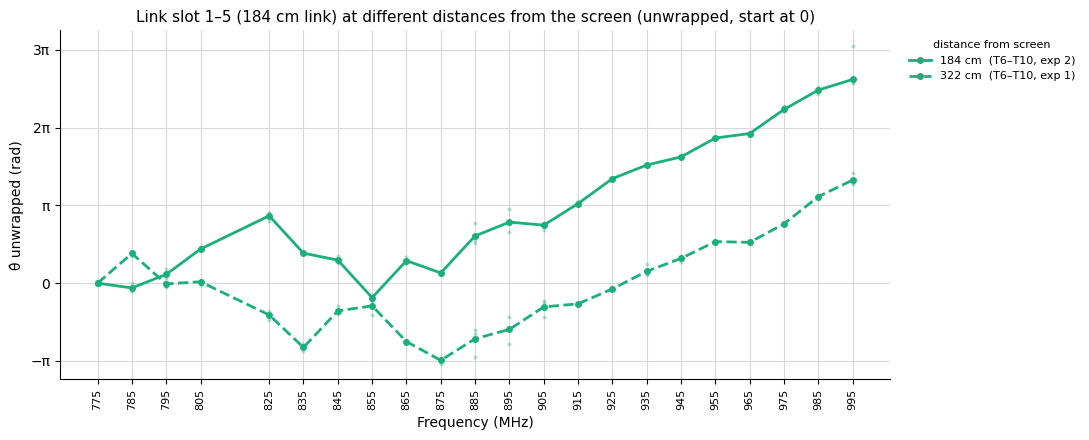

In [153]:
LINKS_184 = [(1, 5)]   # all 184 cm slots: [(1, 5)]
LINK_184 = (1, 5)                  # slot for the link-vs-distance and 3D plots
DISTANCES_184 = None       # cm from screen; None = all
check_link_length(LINKS_184 + [LINK_184], 184)

plot_link_panels(theta_data, "θ̂ (rad)", agg=circmean_mod_pi,
                 ylim=(0, np.pi), yticks=([0, np.pi / 2, np.pi], ["0", "π/2", "π"]), links=LINKS_184,
                 title="184 cm links (4×46 cm)")

print(f"Distances available for link slot {LINK_184}:")
print(available_distances(LINK_184).to_string(index=False))
plot_link_vs_distance(LINK_184, distances=DISTANCES_184)
plot_link_vs_distance(LINK_184, distances=DISTANCES_184, unwrap=True)
plot_link_vs_distance(LINK_184, distances=DISTANCES_184, unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_184, distances=(92,230))
plot_link_vs_distance(LINK_184, distances=(92,230), unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_184, distances=(138,276))
plot_link_vs_distance(LINK_184, distances=(138,276), unwrap=True, zero_start=True)
plot_link_vs_distance(LINK_184, distances=(184,322))
plot_link_vs_distance(LINK_184, distances=(184,322), unwrap=True, zero_start=True)


In [154]:
plot_link_vs_distance_3d(LINK_184, surface=True, unwrap=True)   # distances=DISTANCES_184 to match the 2D plot
plot_link_vs_distance_3d(LINK_184, surface=True, unwrap=True, zero_start=True)
